In [1]:
import os
print(os.name)

posix


In [2]:
import os
import sys
import gym
import math
import skopt
import talib
import shutil
import pickle 
import joblib
import random
import inspect
import platform
import warnings
import subprocess
import numpy as np
import pandas as pd
import yfinance as yf
import pandas_ta as ta
import tensorflow as tf

In [3]:
print("Platform and Pakages ( Version )")
print(f"Platform: {platform.system()} {platform.release()}")
print(f"Environment: {sys.executable}")
print(f"Python Version: {sys.version}")
print(f"Pandas Version: {pd.__version__}")
print(f"Numpy Version: {np.__version__}")
print(f"pandas_ta Version: {ta.version}")
print(f"yfinance Version: {yf.__version__}")
print(f"Gym Version: {gym.__version__}")
print(f"TensorFlow Version: {tf.__version__}")
print(f"Scikit-Optimize Version: {skopt.__version__}")

Platform and Pakages ( Version )
Platform: Darwin 24.3.0
Environment: /Users/mini/Desktop/Projects/FinDRL/xdu/penv/bin/python3.11
Python Version: 3.11.11 (main, Dec  3 2024, 17:20:40) [Clang 16.0.0 (clang-1600.0.26.4)]
Pandas Version: 2.2.3
Numpy Version: 1.23.5
pandas_ta Version: 0.3.14b0
yfinance Version: 0.2.52
Gym Version: 0.26.2
TensorFlow Version: 2.17.1
Scikit-Optimize Version: 0.10.2


In [4]:
import mlflow
from gym import spaces
import mlflow.tensorflow
from typing import Optional
from collections import deque
from skopt import gp_minimize
from itertools import product
from skopt import gp_minimize
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from skopt.space import Integer, Real
from skopt.utils import use_named_args
from datetime import datetime, timedelta
from matplotlib.ticker import PercentFormatter
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import load_model
from pandas.tseries.frequencies import to_offset
from skopt.space import Integer, Categorical, Real
from mlflow.models.signature import infer_signature
from sklearn.model_selection import train_test_split
from tensorflow.keras import models, layers, optimizers

In [5]:
path = "./data"

In [6]:
if not os.path.exists(path):
  os.mkdir(path)

dp = f"{path}/thesis-data.csv" # thesis.csv

# Load or Download Data
if os.path.exists(dp):
    data = pd.read_csv(dp, low_memory=False)
else:
    data = yf.download("^GSPC", interval="1d", period="max", multi_level_index=False)
    # Save if downloaded
    if not os.path.exists(dp):
        data.to_csv(dp)

# Preprocess Data
if 'date' not in data.columns:
    data.reset_index(inplace=True)  # Reset index to bring 'date' as a column

# Convert column names to lowercase
data.columns = data.columns.str.lower()

# Ensure 'date' is the index
data["date"] = pd.to_datetime(data["date"])  # Convert to datetime format
data.set_index("date", inplace=True)
# data = data.drop("unnamed: 0", axis=1)
# data = data.drop("index", axis=1)

In [7]:
data = data[["open", "high", "low", "close", "volume"]]
# data = data[(data.index >= "2015") & (data.index <= "2018")]
# new_data = data.loc[:, data.columns == 'date open high low close volume']

In [8]:
data

,open,high,low,close,volume
date,,,,,
1965-01-05,1257.719971,1257.719971,1257.719971,1257.719971,0
1965-01-06,1263.989990,1263.989990,1263.989990,1263.989990,0
1965-01-07,1274.270020,1274.270020,1274.270020,1274.270020,0
1965-01-08,1286.430054,1286.430054,1286.430054,1286.430054,0
1965-01-12,1288.540039,1288.540039,1288.540039,1288.540039,0
...,...,...,...,...,...
2025-02-20,4695.439941,4764.029785,4675.330078,4761.939941,0
2025-02-21,4766.169922,4790.049805,4755.020020,4775.060059,0
2025-02-24,4774.359863,4774.589844,4678.839844,4678.839844,0


In [9]:
from TA.Indicators import StockIndicators

In [10]:
class DataProcessor:
    """Processes financial data for use in trading systems."""

    def __init__(self, data: pd.DataFrame, timeframe: Optional[str] = None):
        """
        Initialize the DataProcessor.

        Args:
            data (pd.DataFrame): Raw financial data.
            timeframe (Optional[str]): Timeframe for filtering data (e.g., '5YE').
        """
        self.raw_data = data.copy()
        self.timeframe = timeframe
        self._preprocess_data()
        self._validate_data()
        self._clean_data()

    def _preprocess_data(self):
        """Filter data based on the specified timeframe."""
        self.raw_data = self.raw_data.sort_index()

        if self.timeframe:
            offset = to_offset(self.timeframe)
            end_date = self.raw_data.index[-1]
            start_date = end_date - offset
            self.raw_data = self.raw_data.loc[start_date:end_date]

        self.raw_data = self.raw_data.ffill().bfill()

    def _validate_data(self):
        """Validate that required columns are present."""
        required = ['open', 'high', 'low', 'close', 'volume']
        missing = [col for col in required if col not in self.raw_data.columns]
        if missing:
            raise ValueError(f"Missing required columns: {missing}")

    def _clean_data(self):
        """Clean and standardize the data."""
        self.raw_data.columns = self.raw_data.columns.str.lower()
        for col in ['timeframe', 'date']:
            if col in self.raw_data.columns:
                self.raw_data.drop(columns=[col], inplace=True)
        self.raw_data.dropna(inplace=True)
        self.raw_data.reset_index(drop=True, inplace=True)

    def add_technical_indicators(self):
        """Calculate and add technical indicators"""
        df = self.raw_data.copy()
        ind_sys = StockIndicators(df)
        df = ind_sys.run_all_indicators()
        new_cols = ind_sys.get_new_indicator_columns()
        df = ind_sys.clean_data()
        self.raw_data = df
        return self.raw_data, new_cols

In [11]:
warnings.filterwarnings("ignore", category=UserWarning, message="You are saving your model as an HDF5 file...")

class DNNOptimizer:
    """Optimizes and trains a Deep Neural Network for financial data."""

    def __init__(self, input_dim: int):
        """
        Initialize the DNNOptimizer.

        Args:
            input_dim (int): Number of input features.
        """
        self.input_dim = input_dim
        self.scaler = MinMaxScaler()
        self.model = None

    def _build_model(self, num_layers: int = 3, units: int = 128, dropout: float = 0.2, lr: float = 0.001):
        """Build the DNN architecture."""
        model = models.Sequential()
        model.add(layers.Input(shape=(self.input_dim,)))
        for _ in range(num_layers):
            model.add(layers.Dense(units, activation='relu'))
            model.add(layers.Dropout(dropout))
        model.add(layers.Dense(1, activation='linear'))
        model.compile(optimizer=optimizers.Adam(learning_rate=lr), loss='mse', metrics=['mae'])
        return model

    def optimize_hyperparameters(self, X: np.ndarray, y: np.ndarray, n_calls: int = 15):
        """Optimize hyperparameters using Bayesian optimization."""
        dimensions = [
            Integer(2, 5, name='num_layers'),
            Integer(64, 256, name='units'),
            Real(0.1, 0.5, name='dropout'),
            Real(1e-4, 1e-2, name='lr')
        ]

        @use_named_args(dimensions)
        def objective(**params):
            model = self._build_model(**params)
            X_scaled = self.scaler.fit_transform(X)
            X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2)
            
            # Add checkpoint callback
            checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
                filepath="best_model.keras",
                monitor="val_loss",
                save_best_only=True,
                mode="min"
            )
            
            history = model.fit(
                X_train, y_train,
                validation_data=(X_test, y_test),
                epochs=20,
                verbose=0,
                callbacks=[checkpoint_callback]  # Add explicit callback
            )
            return history.history['val_loss'][-1]

        result = gp_minimize(objective, dimensions, n_calls=n_calls, verbose=True)
        self.model = self._build_model(*result.x)
        self.model.fit(self.scaler.fit_transform(X), y, epochs=50, verbose=0)
        return result.x

    def save(self, path: str):
        """Save model in Keras format (.keras)"""
        os.makedirs(path, exist_ok=True)
        # keras.saving.save_model(self.model, os.path.join(path, "dnn_model.h5"))
        self.model.save(os.path.join(path, "dnn_model.keras"))  # Modern format
        joblib.dump(self.scaler, os.path.join(path, 'dnn_scaler.pkl'))

    @classmethod
    def load(cls, path: str):
        """Load from Keras format (.keras)"""
        model = models.load_model(os.path.join(path, "dnn_model.keras"))  # Modern format
        input_dim = model.input_shape[1]
        dnn_optimizer = cls(input_dim)
        dnn_optimizer.model = model
        dnn_optimizer.scaler = joblib.load(os.path.join(path, 'dnn_scaler.pkl'))
        return dnn_optimizer

In [12]:
warnings.filterwarnings("ignore", category=UserWarning, message="You are saving your model as an HDF5 file...")

class TradingEnv(gym.Env):
    """A trading environment for reinforcement learning."""

    def __init__(self, data: pd.DataFrame, features: np.ndarray):
        """
        Initialize the TradingEnv.

        Args:
            data (pd.DataFrame): Financial data.
            features (np.ndarray): Feature matrix.
        """
        self.data = data
        self.features = features
        self.action_space = spaces.Discrete(3)  # 0: hold, 1: buy, 2: sell
        self.observation_space = spaces.Box(low=-np.inf, high=np.inf, shape=(features.shape[1] + 5 + 3,), dtype=np.float32)
        self.reset()

    def reset(self):
        """Reset the environment to its initial state."""
        self.current_step = 0
        self.balance = 10000.0
        self.holdings = 0
        self.trade_history = deque(maxlen=5)
        return self._next_observation()

    def _next_observation(self):
        """Generate the next observation."""
        market_data = self.data.iloc[self.current_step][['open', 'high', 'low', 'close', 'volume']].values.astype(np.float32)
        indicator_data = self.features[self.current_step].astype(np.float32)
        portfolio_state = np.array([self.holdings, self.balance, self.balance + self.holdings * self.data.iloc[self.current_step]['close']], dtype=np.float32)
        return np.concatenate([market_data, indicator_data, portfolio_state])

    def step(self, action: int):
        """Execute a trading action."""
        current_price = self.data.iloc[self.current_step]['close']
        prev_value = self.balance + self.holdings * current_price

        if action == 1 and self.balance > 10:  # Buy
            max_shares = self.balance // (current_price * 1.001)
            self.holdings += max_shares
            self.balance -= max_shares * current_price * 1.001
        elif action == 2 and self.holdings > 0:  # Sell
            self.balance += self.holdings * current_price * 0.999
            self.holdings = 0

        self.current_step += 1
        done = self.current_step >= len(self.data) - 1
        new_price = self.data.iloc[self.current_step]['close'] if not done else current_price
        reward = (self.balance + self.holdings * new_price) - prev_value
        return self._next_observation(), reward, done, {}

In [13]:
warnings.filterwarnings("ignore", category=UserWarning, message="You are saving your model as an HDF5 file...")

class DRLAgent:
    """A Deep Reinforcement Learning agent for trading."""

    def __init__(self, state_size: int, action_size: int):
        """
        Initialize the DRLAgent.

        Args:
            state_size (int): Size of the state space.
            action_size (int): Size of the action space.
        """
        self.state_size = state_size
        self.action_size = action_size
        self.memory = deque(maxlen=2000)
        self.gamma = 0.95
        self.epsilon = 1.0
        self.epsilon_min = 0.01
        self.epsilon_decay = 0.995
        self.model = self._build_model()
        self.target_model = self._build_model()
        self.update_target()

    def _build_model(self):
        """Build the DQN model."""
        model = models.Sequential([
            layers.Dense(64, activation='relu', input_dim=self.state_size),
            layers.BatchNormalization(),
            layers.Dense(32, activation='relu'),
            layers.Dense(self.action_size, activation='linear')
        ])
        model.compile(loss='mse', optimizer=optimizers.Adam(0.001))
        return model

    def update_target(self):
        """Update the target network weights."""
        self.target_model.set_weights(self.model.get_weights())

    def act(self, state: np.ndarray) -> int:
        """Select an action using epsilon-greedy policy."""
        if np.random.rand() <= self.epsilon:
            return random.randrange(self.action_size)
        return np.argmax(self.model.predict(state[np.newaxis], verbose=0)[0])

    def remember(self, state: np.ndarray, action: int, reward: float, next_state: np.ndarray, done: bool):
        """Store experience in replay buffer."""
        self.memory.append((state, action, reward, next_state, done))

    def replay(self, batch_size: int = 32):
        """Train the model using experience replay."""
        if len(self.memory) < batch_size:
            return

        minibatch = random.sample(self.memory, batch_size)
        states = np.array([t[0] for t in minibatch])
        next_states = np.array([t[3] for t in minibatch])

        targets = self.model.predict(states)
        next_q_values = self.target_model.predict(next_states)

        for i, (_, action, reward, _, done) in enumerate(minibatch):
            targets[i][action] = reward if done else reward + self.gamma * np.max(next_q_values[i])

        self.model.fit(states, targets, epochs=1, verbose=0)
        self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)

    def save_model(self, path: str):
        """Save agent in Keras format (.keras)"""
        os.makedirs(path, exist_ok=True)
        self.model.save(os.path.join(path, "drl_model.keras"))  # Modern format
        # keras.saving.save_model(self.model, os.path.join(path, "drl_model.h5"))

    @classmethod
    def load(cls, path: str):
        """Load from Keras format (.keras)"""
        model = models.load_model(os.path.join(path, "drl_model.keras"))  # Modern format
        agent = cls(model.input_shape[1], model.output_shape[1])
        agent.model = model
        agent.update_target()
        return agent

In [14]:
warnings.filterwarnings("ignore", category=UserWarning, message="You are saving your model as an HDF5 file...")

class FinDRLSystem:
    """Trading system with centralized directory management."""
    def __init__(
        self, 
        data: pd.DataFrame, 
        timeframe: Optional[str] = '5YE',
        base_dir: str = os.path.join(os.getcwd(), "data")  # Single base directory for all outputs
    ):
        """
        Args:
            base_dir (str): Root directory for models, logs, and artifacts.
        """
        self.base_dir = os.path.abspath(base_dir)
        self._create_directories()
        self._setup_mlflow()
        self.processor = DataProcessor(data, timeframe)
        self.data, indicator_cols = self.processor.add_technical_indicators()
        self.X = self.data[indicator_cols].values
        self.y = self.data['close'].pct_change().shift(-1).fillna(0).values
        self.prices = self.data['close'].values
        self.dnn_optimizer = DNNOptimizer(self.X.shape[1])
        self.dnn_optimizer.optimize_hyperparameters(self.X, self.y)
        self.features = self.dnn_optimizer.model.predict(self.dnn_optimizer.scaler.transform(self.X))
        self.env = TradingEnv(self.data, self.features)
        self.agent = DRLAgent(self.env.observation_space.shape[0], self.env.action_space.n)
        self.training_loss = []
        self.sharpe_ratios = []
        self.max_drawdowns = []
        self.episode_rewards = []
        self.episode_actions = []
        self.portfolio_history = []

    def _create_directories(self):
        """Create all required subdirectories under base_dir."""
        os.makedirs(f"{self.base_dir}/models/mlruns", exist_ok=True)  # MLflow logs
        os.makedirs(f"{self.base_dir}/models/native", exist_ok=True)  # Saved models
        os.makedirs(f"{self.base_dir}/models/artifacts", exist_ok=True)  # Performance plots

    def _setup_mlflow(self):
        """Configure MLflow to use the base directory."""
        mlflow.set_tracking_uri(f"file://{self.base_dir}/models/mlruns")
        mlflow.set_experiment("FinDRL")
        mlflow.tensorflow.autolog(
            log_input_examples=True,
            log_model_signatures=True,
            log_models=False,  # Disable automatic model logging
            registered_model_name="FinDRL"
        )

    def train(self, episodes: int = 100, batch_size: int = 128):
        """Train the DRL agent."""
        with mlflow.start_run():
            mlflow.log_artifact("best_model.keras")
            mlflow.log_params({
                "timeframe": self.processor.timeframe,
                "episodes": episodes,
                "batch_size": batch_size,
                "dnn_input_dim": self.dnn_optimizer.input_dim,
                "drl_state_size": self.agent.state_size,
                "drl_action_size": self.agent.action_size
            })

            for episode in range(episodes):
                state = self.env.reset()
                total_reward = 0
                episode_actions = []
                episode_portfolio = []

                while True:
                    current_value = self.env.balance + self.env.holdings * self.env.data.iloc[self.env.current_step]['close']
                    episode_portfolio.append(current_value)
                    action = self.agent.act(state)
                    episode_actions.append(action)
                    next_state, reward, done, _ = self.env.step(action)
                    self.agent.remember(state, action, reward, next_state, done)
                    state = next_state
                    total_reward += reward
                    if done:
                        final_value = self.env.balance + self.env.holdings * self.env.data.iloc[-1]['close']
                        episode_portfolio.append(final_value)
                        break

                self.episode_rewards.append(total_reward)
                self.episode_actions.append(episode_actions)
                self.portfolio_history.append(episode_portfolio)
                print(f"Episode {episode+1}/{episodes} | Reward: ${total_reward:.2f}")
                mlflow.log_metrics({
                    "episode_reward": total_reward,
                    "sharpe_ratio": self._calculate_sharpe_ratio(episode),
                    "max_drawdown": self._calculate_max_drawdown(episode),
                    "epsilon": self.agent.epsilon
                }, step=episode)

            self._log_mlflow_models()
            self._log_mlflow_artifacts()

    def _calculate_sharpe_ratio(self, episode_idx: int) -> float:
        """Calculate the Sharpe ratio for an episode."""
        returns = np.diff(self.portfolio_history[episode_idx]) / self.portfolio_history[episode_idx][:-1]
        if np.std(returns) == 0:
            return 0
        return np.sqrt(252) * np.mean(returns) / np.std(returns)

    def _calculate_max_drawdown(self, episode_idx: int) -> float:
        """Calculate the maximum drawdown for an episode."""
        portfolio = np.array(self.portfolio_history[episode_idx])
        peak = np.maximum.accumulate(portfolio)
        trough = portfolio[np.argmax(peak - portfolio)]
        return (peak[np.argmax(peak - portfolio)] - trough) / peak[np.argmax(peak - portfolio)]

    # def _log_mlflow_models(self):
    #     """Log trained models to MLflow."""
    #     mlflow.tensorflow.log_model(self.dnn_optimizer.model, "dnn_model", registered_model_name="FinDRL-DNN")
    #     mlflow.tensorflow.log_model(self.agent.model, "drl_agent", registered_model_name="FinDRL-Agent")
    def _log_mlflow_models(self):
        """Log models in Keras format to MLflow"""
        # Log DNN
        mlflow.tensorflow.log_model(
            self.dnn_optimizer.model,
            "dnn_model",
            registered_model_name="FinDRL-DNN",
            extra_pip_requirements=["tensorflow>=2.16"]  # Ensure compatibility
        )
        
        # Log DRL agent
        mlflow.tensorflow.log_model(
            self.agent.model,
            "drl_agent",
            registered_model_name="FinDRL-Agent",
            extra_pip_requirements=["tensorflow>=2.16"]
        )

    def _log_mlflow_artifacts(self):
        """Save and log performance artifacts."""
        artifact_path = "./data/models/artifacts"
        os.makedirs(artifact_path, exist_ok=True)
        self.plot_full_analysis()
        plt.savefig(f"{artifact_path}/full_analysis.png")
        plt.close()
        self.plot_model_performance()
        plt.savefig(f"{artifact_path}/model_performance.png")
        plt.close()
        mlflow.log_artifacts(artifact_path, "performance_plots")
        shutil.rmtree(artifact_path)

    def plot_max_drawdown(self, episode_idx: int = -1):
        """Plot the drawdown curve for a specific episode."""
        portfolio = self.portfolio_history[episode_idx]
        rolling_max = np.maximum.accumulate(portfolio)
        drawdown = (rolling_max - portfolio) / rolling_max

        plt.figure(figsize=(12, 6))
        plt.fill_between(range(len(drawdown)), drawdown * 100, color='red', alpha=0.3)
        plt.plot(drawdown * 100, color='darkred')
        plt.title(f"Drawdown Curve (Episode {episode_idx+1})")
        plt.ylabel("Drawdown (%)")
        plt.xlabel("Time Step")
        plt.gca().yaxis.set_major_formatter(PercentFormatter())
        plt.grid(True)
        plt.show()

    def plot_sharpe_ratio(self):
        """Plot the evolution of Sharpe ratios across episodes."""
        self.sharpe_ratios = [self._calculate_sharpe_ratio(i) for i in range(len(self.portfolio_history))]
        plt.figure(figsize=(12, 6))
        plt.plot(self.sharpe_ratios, marker='o', linestyle='-', color='blue')
        plt.title("Sharpe Ratio Evolution")
        plt.xlabel("Episode")
        plt.ylabel("Annualized Sharpe Ratio")
        plt.grid(True)
        plt.show()

    def plot_model_performance(self):
        """Visualize key performance metrics."""
        if not self.portfolio_history:
            print("No training data available!")
            return

        sharpe_ratios = []
        max_drawdowns = []
        annual_returns = []

        for portfolio in self.portfolio_history:
            returns = np.diff(portfolio) / portfolio[:-1]
            sharpe = np.sqrt(252) * np.mean(returns) / np.std(returns) if len(returns) > 0 and np.std(returns) > 0 else 0
            sharpe_ratios.append(sharpe)

            peak = np.maximum.accumulate(portfolio)
            trough = portfolio[np.argmax(peak - portfolio)]
            drawdown = (peak[np.argmax(peak - portfolio)] - trough) / peak[np.argmax(peak - portfolio)]
            max_drawdowns.append(drawdown)

            annual_returns.append((portfolio[-1]/portfolio[0])**(252/len(portfolio)) - 1)

        fig, axs = plt.subplots(2, 2, figsize=(16, 12))

        # Sharpe Ratio Evolution
        axs[0, 0].plot(sharpe_ratios, color='blue', marker='o')
        axs[0, 0].set_title('Sharpe Ratio Evolution')
        axs[0, 0].set_ylabel('Annualized Sharpe Ratio')
        axs[0, 0].grid(True)

        # Max Drawdown Progression
        axs[0, 1].plot(np.array(max_drawdowns) * 100, color='red', marker='s')
        axs[0, 1].set_title('Maximum Drawdown')
        axs[0, 1].set_ylabel('Drawdown (%)')
        axs[0, 1].grid(True)

        # Annualized Returns
        axs[1, 0].plot(np.array(annual_returns) * 100, color='green', marker='^')
        axs[1, 0].set_title('Annualized Returns')
        axs[1, 0].set_ylabel('Return (%)')
        axs[1, 0].grid(True)

        # Risk-Return Profile
        axs[1, 1].scatter(np.array(max_drawdowns) * 100, np.array(annual_returns) * 100, c=sharpe_ratios, cmap='viridis')
        axs[1, 1].set_title('Risk-Return Profile')
        axs[1, 1].set_xlabel('Max Drawdown (%)')
        axs[1, 1].set_ylabel('Annual Return (%)')
        axs[1, 1].grid(True)
        plt.colorbar(axs[1, 1].collections[0], ax=axs[1, 1], label='Sharpe Ratio')

        plt.tight_layout()
        plt.show()

    def plot_full_analysis(self, episode_idx: int = -1):
        """Comprehensive performance dashboard."""
        plt.figure(figsize=(18, 15))

        # Trading Signals
        plt.subplot(3, 2, 1)
        self._plot_trading_actions(episode_idx)

        # Learning Curve
        plt.subplot(3, 2, 2)
        self.plot_learning_curve()

        # Max Drawdown
        plt.subplot(3, 2, 3)
        self.plot_max_drawdown(episode_idx)

        # Sharpe Ratio
        plt.subplot(3, 2, 4)
        self.plot_sharpe_ratio()

        # Model Performance
        plt.subplot(3, 2, 5)
        self.plot_model_performance()

        # Portfolio Growth
        plt.subplot(3, 2, 6)
        self._plot_portfolio_growth(episode_idx)

        plt.tight_layout()
        plt.show()

    def plot_learning_curve(self):
        """Plot training performance over episodes."""
        plt.figure(figsize=(10, 5))
        plt.plot(self.episode_rewards)
        plt.title("Training Performance")
        plt.xlabel("Episode")
        plt.ylabel("Total Reward")
        plt.grid(True)
        plt.show()

    def plot_trading_actions(self, episode_idx: int = -1):
        """Visualize trading signals for a specific episode."""
        if not self.episode_actions:
            print("No trading actions recorded!")
            return

        actions = self.episode_actions[episode_idx]
        valid_length = min(len(actions), len(self.prices) - 1)
        buy_signals = [i for i, a in enumerate(actions[:valid_length]) if a == 1]
        sell_signals = [i for i, a in enumerate(actions[:valid_length]) if a == 2]

        plt.figure(figsize=(15, 5))
        plt.plot(self.prices[:valid_length + 1], label='Price')

        if isinstance(self.data.index, pd.DatetimeIndex):
            plt.scatter(self.data.index[buy_signals], self.prices[buy_signals], color='green', marker='^', label='Buy', s=100)
            plt.scatter(self.data.index[sell_signals], self.prices[sell_signals], color='red', marker='v', label='Sell', s=100)
        else:
            plt.scatter(buy_signals, self.prices[buy_signals], color='green', marker='^', label='Buy', s=100)
            plt.scatter(sell_signals, self.prices[sell_signals], color='red', marker='v', label='Sell', s=100)

        plt.title(f"Trading Signals - Episode {episode_idx + 1}")
        plt.xlabel("Date" if isinstance(self.data.index, pd.DatetimeIndex) else "Step")
        plt.ylabel("Price")
        plt.legend()
        plt.grid(True)
        plt.show()

    def _plot_trading_actions(self, episode_idx: int = -1, ax=None):
        """Internal method to plot price and trading actions."""
        if not self.episode_actions:
            print("No trading actions recorded!")
            return

        actions = self.episode_actions[episode_idx]
        valid_length = min(len(actions), len(self.prices) - 1)
        buy_signals = [i for i, a in enumerate(actions[:valid_length]) if a == 1]
        sell_signals = [i for i, a in enumerate(actions[:valid_length]) if a == 2]

        ax = ax or plt.gca()
        ax.plot(self.prices[:valid_length + 1], label='Price', alpha=0.8)
        ax.scatter(buy_signals, self.prices[buy_signals], color='green', marker='^', label='Buy', s=100)
        ax.scatter(sell_signals, self.prices[sell_signals], color='red', marker='v', label='Sell', s=100)
        ax.set_title(f"Trading Signals - Episode {episode_idx + 1}")
        ax.legend()
        ax.grid(True)

    def _plot_portfolio_growth(self, episode_idx: int = -1):
        """Plot portfolio value over time."""
        portfolio = self.portfolio_history[episode_idx]
        plt.plot(portfolio, label='Portfolio Value', color='purple')
        plt.title("Portfolio Growth")
        plt.xlabel("Time Step")
        plt.ylabel("Value ($)")
        plt.grid(True)
        plt.legend()

    def save_models(self, directory: str):
        """Save all system components."""
        os.makedirs(directory, exist_ok=True)
        self.dnn_optimizer.save(os.path.join(directory, 'dnn'))
        self.agent.save_model(os.path.join(directory, 'drl'))

    @classmethod
    def load(cls, new_data: pd.DataFrame, directory: str, timeframe: Optional[str] = '5YE'):
        """Load trained system with new data."""
        processor = DataProcessor(new_data, timeframe)
        data_with_indicators = processor.add_technical_indicators()[0]
        dnn_optimizer = DNNOptimizer.load(os.path.join(directory, 'dnn'))

        try:
            X = data_with_indicators[dnn_optimizer.scaler.feature_names_in_]
        except KeyError as e:
            raise ValueError(f"Feature mismatch in new data: {e}")

        features = dnn_optimizer.model.predict(dnn_optimizer.scaler.transform(X))
        system = cls.__new__(cls)
        system.__dict__.update({
            'processor': processor,
            'data': data_with_indicators,
            'dnn_optimizer': dnn_optimizer,
            'env': TradingEnv(data_with_indicators, features),
            'agent': DRLAgent.load(os.path.join(directory, 'drl')),
            'prices': data_with_indicators['close'].values,
            'episode_rewards': [],
            'episode_actions': []
        })
        return system

    @classmethod
    def load_production_model(cls, data: pd.DataFrame):
        """Load production models from MLflow."""
        mlflow.set_tracking_uri("file://./data/models/mlruns")
        dnn_model = mlflow.tensorflow.load_model("models:/FinDRL-DNN/Production")
        drl_model = mlflow.tensorflow.load_model("models:/FinDRL-Agent/Production")

        system = cls.__new__(cls)
        system.dnn_optimizer = DNNOptimizer(dnn_model.input_shape[1])
        system.dnn_optimizer.model = dnn_model
        system.agent = DRLAgent(drl_model.input_shape[1], drl_model.output_shape[1])
        system.agent.model = drl_model
        system._post_load_setup(data)
        return system

    def _post_load_setup(self, data: pd.DataFrame):
        """Reinitialize system components after loading."""
        self.processor = DataProcessor(data)
        self.data, indicator_cols = self.processor.add_technical_indicators()
        self.X = self.data[indicator_cols].values
        self.features = self.dnn_optimizer.model.predict(self.dnn_optimizer.scaler.transform(self.X))
        self.env = TradingEnv(self.data, self.features)
        self.prices = self.data['close'].values
        self.portfolio_history = []

    def save_models(self):
        """Save models to local directory (MLflow compatible)."""
        self.dnn_optimizer.save(f"{self.base_dir}/models/native/dnn")
        self.agent.save_model(f"{self.base_dir}/models/native/drl")
        self._log_mlflow_models()
        self._log_mlflow_artifacts()

Running: bollinger_bands
Running: donchian_channel
Running: fibonacci
Running: gaussian_channel
Running: get_new_indicator_columns
Running: macd
Running: momentum
Running: parabolic_sar
Running: rsi
Running: supertrend
Running: williams_r


2025/03/06 03:03:30 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID 'a665181179454946b112001295f8522b', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current tensorflow workflow


Iteration No: 1 started. Evaluating function at random point.


2025/03/06 03:04:08 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID 'ec5ebedb90a14175b53bde8ee13dc196', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current tensorflow workflow


Iteration No: 1 ended. Evaluation done at random point.
Time taken: 38.2755
Function value obtained: 520598304.0000
Current minimum: 520598304.0000
Iteration No: 2 started. Evaluating function at random point.


...

/Users/mini/Desktop/Projects/FinDRL/xdu/penv/lib/python3.11/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Episode 1/2 | Reward: $-31667818456567224388558017410468295519973987055404817748953384500510209412584104001683486741616171614672380952252948623866099858575431041024.00


/var/folders/g5/c70klxk57jg18s9_sjw7dztr0000gn/T/ipykernel_91232/3740696263.py:51: RuntimeWarning: overflow encountered in double_scalars
  reward = (self.balance + self.holdings * new_price) - prev_value
/var/folders/g5/c70klxk57jg18s9_sjw7dztr0000gn/T/ipykernel_91232/3740696263.py:32: RuntimeWarning: overflow encountered in double_scalars
  portfolio_state = np.array([self.holdings, self.balance, self.balance + self.holdings * self.data.iloc[self.current_step]['close']], dtype=np.float32)
/var/folders/g5/c70klxk57jg18s9_sjw7dztr0000gn/T/ipykernel_91232/2891460545.py:72: RuntimeWarning: overflow encountered in double_scalars
  current_value = self.env.balance + self.env.holdings * self.env.data.iloc[self.env.current_step]['close']
/var/folders/g5/c70klxk57jg18s9_sjw7dztr0000gn/T/ipykernel_91232/3740696263.py:38: RuntimeWarning: overflow encountered in double_scalars
  prev_value = self.balance + self.holdings * current_price
/var/folders/g5/c70klxk57jg18s9_sjw7dztr0000gn/T/ipykernel_9

Episode 2/2 | Reward: $nan


2025/03/06 03:17:21 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.
Registered model 'FinDRL-DNN' already exists. Creating a new version of this model...
Created version '3' of model 'FinDRL-DNN'.
2025/03/06 03:17:21 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.
2025/03/06 03:17:24 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.
Registered model 'FinDRL-Agent' already exists. Creating a new version of this model...
Created version '3' of model 'FinDRL-Agent'.


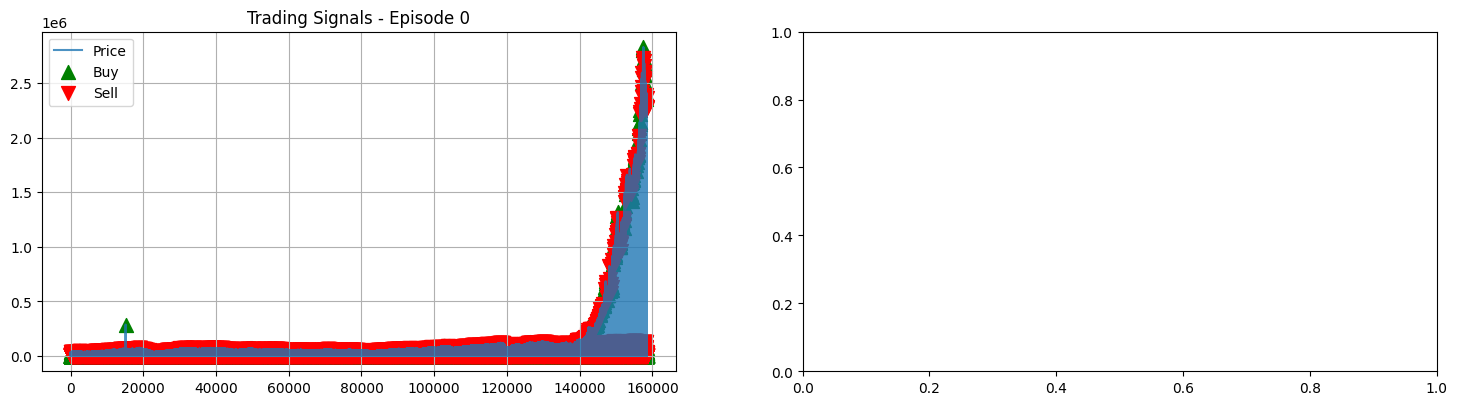

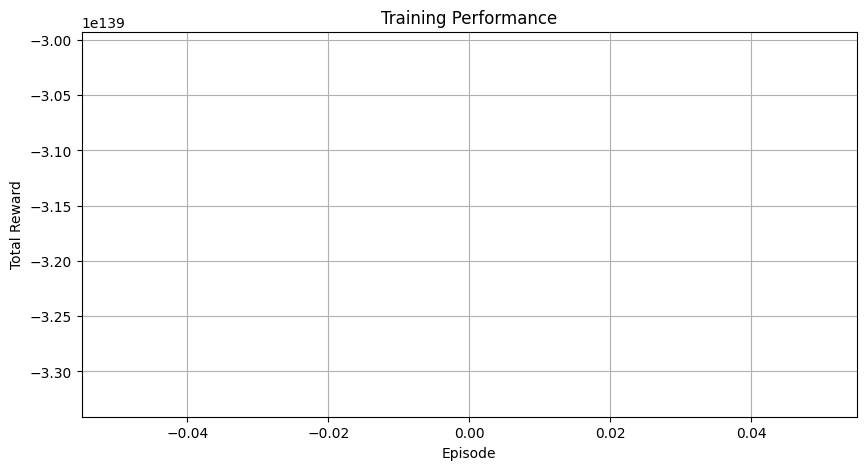

/var/folders/g5/c70klxk57jg18s9_sjw7dztr0000gn/T/ipykernel_91232/2891460545.py:152: RuntimeWarning: invalid value encountered in subtract
  drawdown = (rolling_max - portfolio) / rolling_max
/var/folders/g5/c70klxk57jg18s9_sjw7dztr0000gn/T/ipykernel_91232/2891460545.py:152: RuntimeWarning: invalid value encountered in divide
  drawdown = (rolling_max - portfolio) / rolling_max


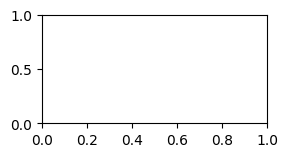

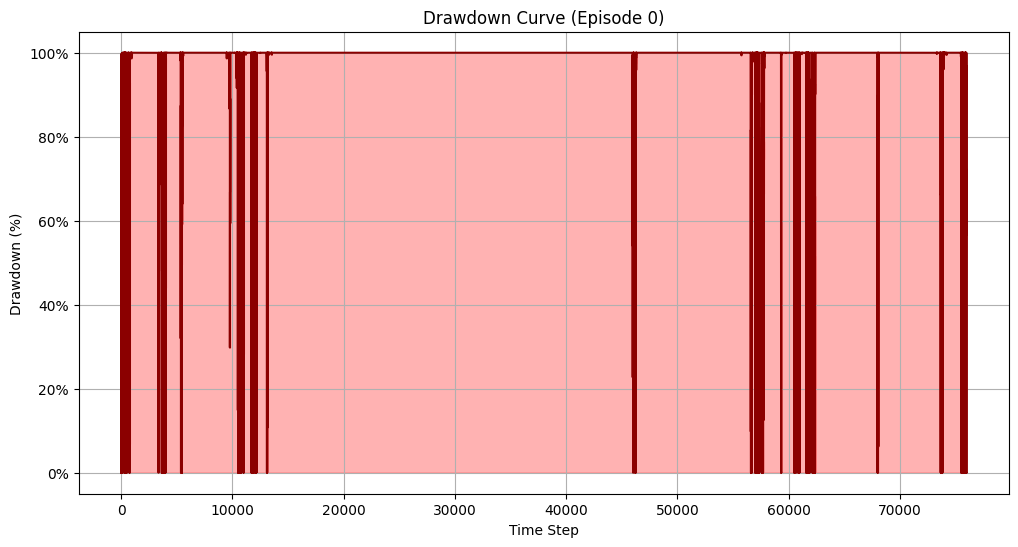

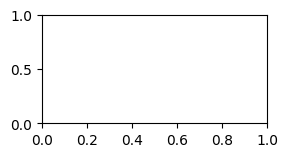

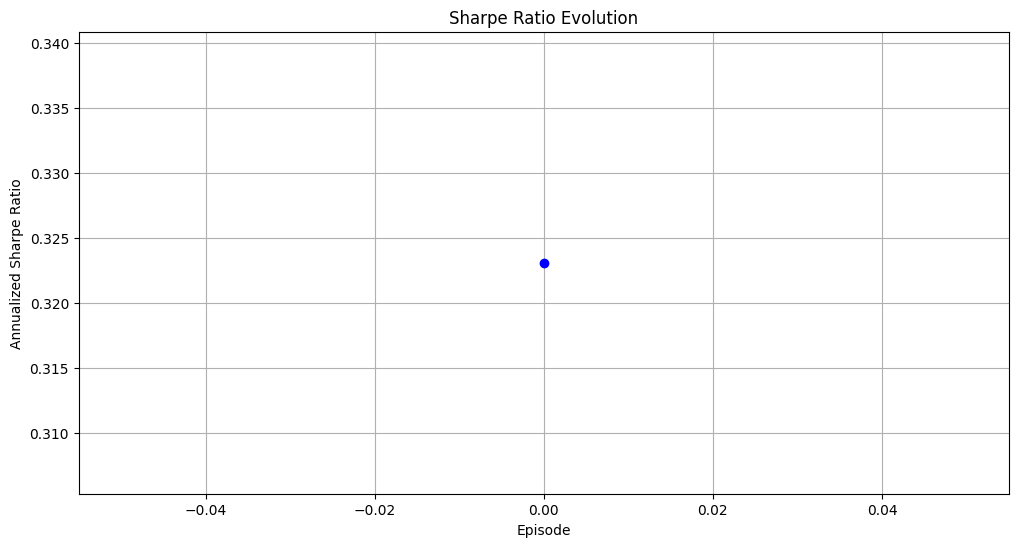

/var/folders/g5/c70klxk57jg18s9_sjw7dztr0000gn/T/ipykernel_91232/2891460545.py:186: RuntimeWarning: invalid value encountered in divide
  returns = np.diff(portfolio) / portfolio[:-1]
/var/folders/g5/c70klxk57jg18s9_sjw7dztr0000gn/T/ipykernel_91232/2891460545.py:191: RuntimeWarning: invalid value encountered in subtract
  trough = portfolio[np.argmax(peak - portfolio)]
/var/folders/g5/c70klxk57jg18s9_sjw7dztr0000gn/T/ipykernel_91232/2891460545.py:192: RuntimeWarning: invalid value encountered in subtract
  drawdown = (peak[np.argmax(peak - portfolio)] - trough) / peak[np.argmax(peak - portfolio)]
/var/folders/g5/c70klxk57jg18s9_sjw7dztr0000gn/T/ipykernel_91232/2891460545.py:192: RuntimeWarning: invalid value encountered in double_scalars
  drawdown = (peak[np.argmax(peak - portfolio)] - trough) / peak[np.argmax(peak - portfolio)]


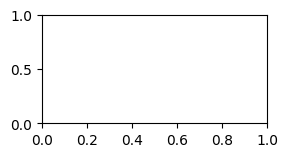

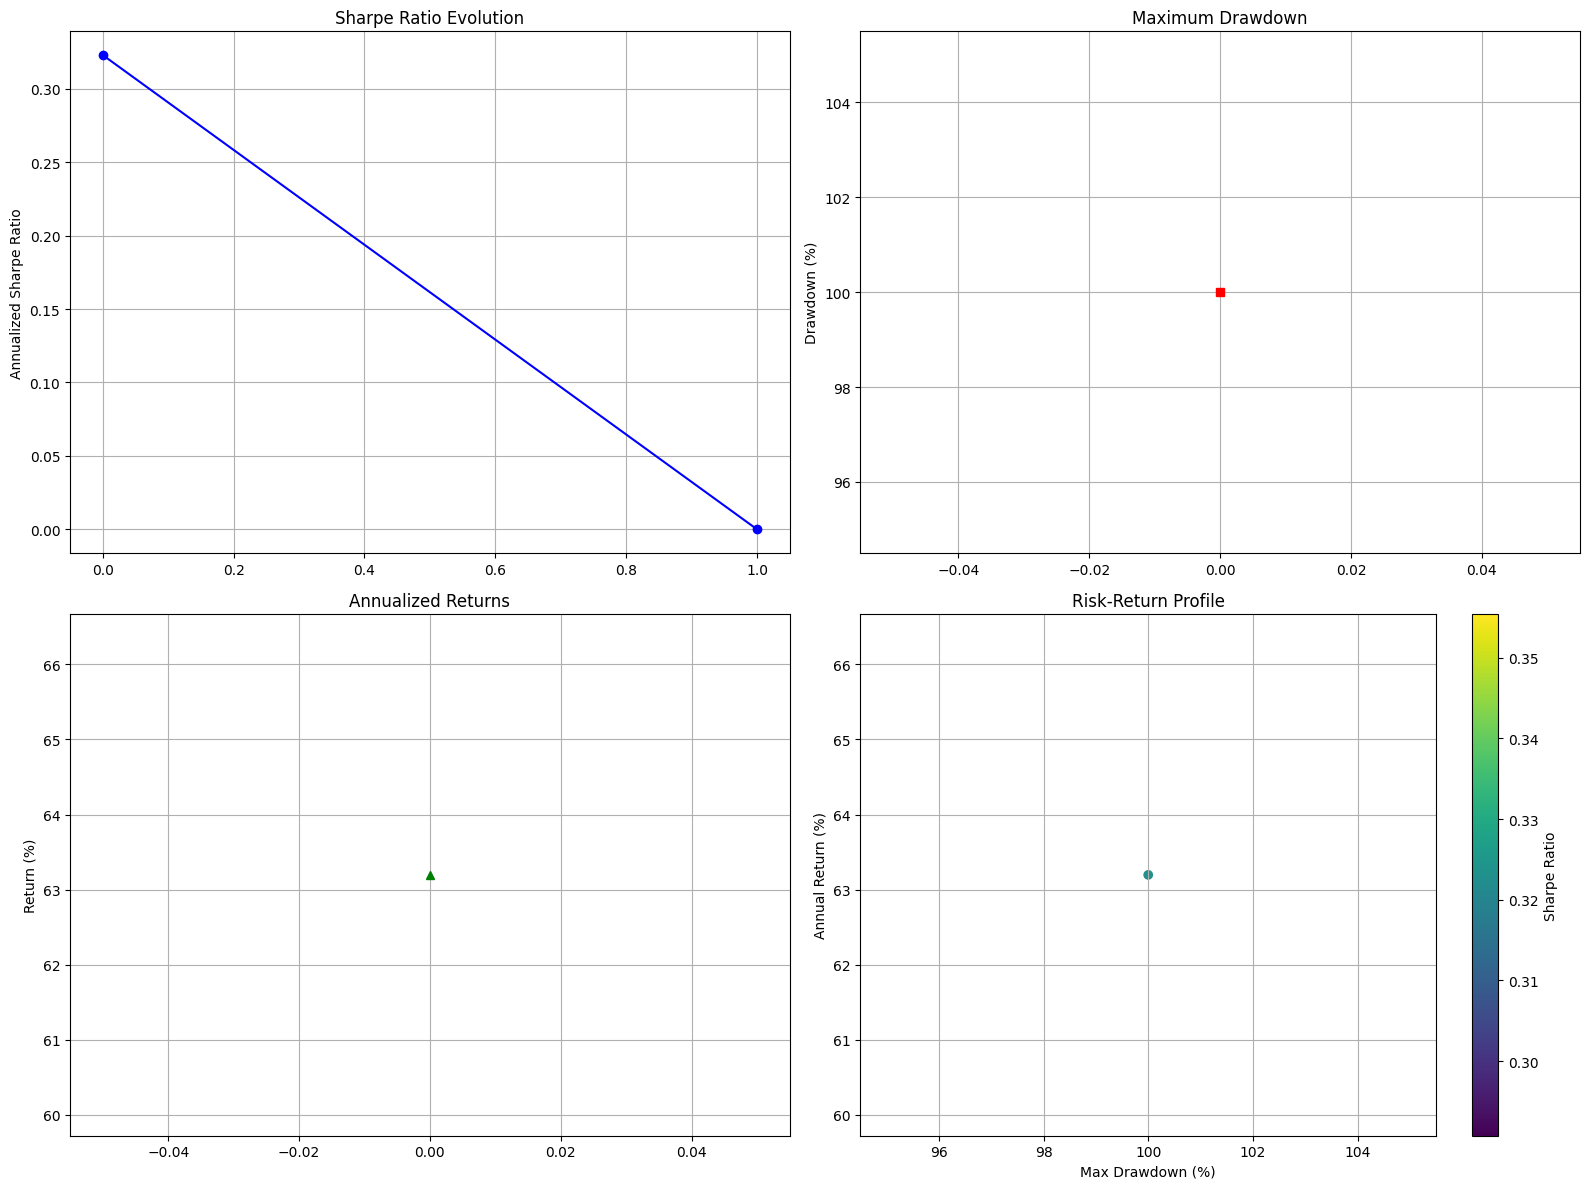

/Users/mini/Desktop/Projects/FinDRL/xdu/penv/lib/python3.11/site-packages/matplotlib/ticker.py:2176: RuntimeWarning: overflow encountered in multiply
  steps = self._extended_steps * scale
/Users/mini/Desktop/Projects/FinDRL/xdu/penv/lib/python3.11/site-packages/matplotlib/ticker.py:2218: RuntimeWarning: overflow encountered in double_scalars
  high = edge.ge(_vmax - best_vmin)


ValueError: arange: cannot compute length

Error in callback <function _draw_all_if_interactive at 0x3431f6fc0> (for post_execute), with arguments args (),kwargs {}:


ValueError: arange: cannot compute length

ValueError: arange: cannot compute length

<Figure size 640x480 with 1 Axes>

In [15]:
trading_system = FinDRLSystem(data, timeframe='20YE')

# Train the model
trading_system.train(episodes=2, batch_size=128)

# Save the trained models
# trading_system.save_models('./data/models')


In [1]:
# # =====================
# # Data Processor
# # =====================
# class DataProcessor:
#     def __init__(self, data: pd.DataFrame, timeframe: str = None):
#         self.raw_data = data.copy()
#         self.timeframe = timeframe
#         self._preprocess_data()
#         self._validate_data()
#         self._clean_data()
        
#     def _preprocess_data(self):
#         """Modern timeframe filtering with pandas.to_offset"""
#         self.raw_data = self.raw_data.sort_index()
        
#         if self.timeframe:
#             # Get offset using top-level pandas function
#             offset = to_offset(self.timeframe)
#             end_date = self.raw_data.index[-1]
#             start_date = end_date - offset
            
#             # Filter using .loc
#             self.raw_data = self.raw_data.loc[start_date:end_date]
        
#         self.raw_data = self.raw_data.ffill().bfill()
        
#     def _validate_data(self):
#         """Validate required columns exist"""
#         required = ['open', 'high', 'low', 'close', 'volume']
#         missing = [col for col in required if col not in self.raw_data.columns]
#         if missing:
#             raise ValueError(f"Missing required columns: {missing}")

#     def _clean_data(self):
#         """Clean and standardize data format"""
#         # Standardize column names
#         self.raw_data.columns = self.raw_data.columns.str.lower()
        
#         # Remove unnecessary columns
#         for col in ['timeframe', 'date']:
#             if col in self.raw_data.columns:
#                 self.raw_data.drop(columns=[col], inplace=True)
                
#         # Final cleanup
#         self.raw_data.dropna(inplace=True)
#         self.raw_data.reset_index(drop=True, inplace=True)
            
#     def add_technical_indicators(self):
#         """Calculate and add technical indicators"""
#         df = self.raw_data.copy()
#         ind_sys = StockIndicators(df)
#         df = ind_sys.run_all_indicators()
#         new_cols = ind_sys.get_new_indicator_columns()
#         df = ind_sys.clean_data()
#         self.raw_data = df
#         return self.raw_data, new_cols

# # =====================
# # DNN Optimizer
# # =====================
# class DNNOptimizer:
#     def __init__(self, input_dim: int):
#         self.input_dim = input_dim
#         self.scaler = MinMaxScaler()
#         self.model = None

#     def _build_model(self, num_layers=3, units=128, dropout=0.2, lr=0.001):
#         """Construct DNN architecture"""
#         model = models.Sequential()
#         model.add(layers.Input(shape=(self.input_dim,)))
#         for _ in range(num_layers):
#             model.add(layers.Dense(units, activation='relu'))
#             model.add(layers.Dropout(dropout))
#         model.add(layers.Dense(1, activation='linear'))
#         model.compile(
#             optimizer=optimizers.Adam(learning_rate=lr),
#             loss='mse',
#             metrics=['mae']
#         )
#         return model

#     def optimize_hyperparameters(self, X, y, n_calls=15):
#         """Bayesian hyperparameter optimization"""
#         dimensions = [
#             Integer(2, 5, name='num_layers'),
#             Integer(64, 256, name='units'),
#             Real(0.1, 0.5, name='dropout'),
#             Real(1e-4, 1e-2, name='lr')
#         ]

#         @use_named_args(dimensions)
#         def objective(**params):
#             """Optimization objective function"""
#             model = self._build_model(**params)
#             X_scaled = self.scaler.fit_transform(X)
#             X_train, X_test, y_train, y_test = train_test_split(
#                 X_scaled, y, test_size=0.2
#             )
#             history = model.fit(
#                 X_train, y_train,
#                 validation_data=(X_test, y_test),
#                 epochs=20,
#                 verbose=0
#             )
#             return history.history['val_loss'][-1]

#         result = gp_minimize(objective, dimensions, n_calls=n_calls, verbose=True)
#         self.model = self._build_model(*result.x)
#         self.model.fit(self.scaler.fit_transform(X), y, epochs=50, verbose=0)
#         return result.x

#     def save(self, path):
#         """Save model and scaler"""
#         os.makedirs(path, exist_ok=True)
#         self.model.save(os.path.join(path, 'dnn_model.keras'))
#         joblib.dump(self.scaler, os.path.join(path, 'dnn_scaler.pkl'))

#     @classmethod
#     def load(cls, path):
#         """Load saved model and scaler"""
#         model = models.load_model(os.path.join(path, 'dnn_model.keras'))
#         input_dim = model.input_shape[1]
#         dnn_optimizer = cls(input_dim)
#         dnn_optimizer.model = model
#         dnn_optimizer.scaler = joblib.load(os.path.join(path, 'dnn_scaler.pkl'))
#         return dnn_optimizer

# # =====================
# # Trading Environment
# # =====================
# class TradingEnv(gym.Env):
#     def __init__(self, data: pd.DataFrame, features: np.ndarray):
#         self.data = data
#         self.features = features
#         self.action_space = spaces.Discrete(3)  # 0: hold, 1: buy, 2: sell
#         self.observation_space = spaces.Box(
#             low=-np.inf, 
#             high=np.inf,
#             shape=(features.shape[1] + 5 + 3,),
#             dtype=np.float32
#         )
#         self.reset()

#     def reset(self):
#         """Reset environment to initial state"""
#         self.current_step = 0
#         self.balance = 100000.0
#         self.holdings = 0
#         self.trade_history = deque(maxlen=5)
#         return self._next_observation()

#     def _next_observation(self):
#         """Construct next observation vector"""
#         market_data = self.data.iloc[self.current_step][
#             ['open', 'high', 'low', 'close', 'volume']
#         ].values.astype(np.float32)
        
#         indicator_data = self.features[self.current_step].astype(np.float32)
        
#         portfolio_state = np.array([
#             self.holdings,
#             self.balance,
#             self.balance + self.holdings * self.data.iloc[self.current_step]['close']
#         ], dtype=np.float32)
        
#         return np.concatenate([market_data, indicator_data, portfolio_state])

#     def step(self, action):
#         """Execute trading action and return new state"""
#         current_price = self.data.iloc[self.current_step]['close']
#         prev_value = self.balance + self.holdings * current_price

#         # Execute trade with transaction costs
#         if action == 1 and self.balance > 10:  # Buy
#             max_shares = self.balance // (current_price * 1.001)
#             self.holdings += max_shares
#             self.balance -= max_shares * current_price * 1.001
#         elif action == 2 and self.holdings > 0:  # Sell
#             self.balance += self.holdings * current_price * 0.999
#             self.holdings = 0

#         self.current_step += 1
#         done = self.current_step >= len(self.data) - 1
        
#         # Calculate reward based on new portfolio value
#         new_price = self.data.iloc[self.current_step]['close'] if not done else current_price
#         reward = (self.balance + self.holdings * new_price) - prev_value
        
#         return self._next_observation(), reward, done, {}

# # =====================
# # DRL Agent
# # =====================
# class DRLAgent:
#     def __init__(self, state_size: int, action_size: int):
#         self.state_size = state_size
#         self.action_size = action_size
#         self.memory = deque(maxlen=2000)
#         self.gamma = 0.95
#         self.epsilon = 1.0
#         self.epsilon_min = 0.01
#         self.epsilon_decay = 0.995
#         self.model = self._build_model()
#         self.target_model = self._build_model()
#         self.update_target()

#     def _build_model(self):
#         """Build DQN network architecture"""
#         model = models.Sequential([
#             layers.Dense(64, activation='relu', input_dim=self.state_size),
#             layers.BatchNormalization(),
#             layers.Dense(32, activation='relu'),
#             layers.Dense(self.action_size, activation='linear')
#         ])
#         model.compile(loss='mse', optimizer=optimizers.Adam(0.001))
#         return model

#     def update_target(self):
#         """Update target network weights"""
#         self.target_model.set_weights(self.model.get_weights())

#     def act(self, state: np.ndarray) -> int:
#         """Epsilon-greedy action selection"""
#         if np.random.rand() <= self.epsilon:
#             return random.randrange(self.action_size)
#         return np.argmax(self.model.predict(state[np.newaxis], verbose=0)[0])

#     def remember(self, state, action, reward, next_state, done):
#         """Store experience in replay buffer"""
#         self.memory.append((state, action, reward, next_state, done))

#     def replay(self, batch_size=32):
#         """Experience replay training"""
#         if len(self.memory) < batch_size:
#             return
        
#         minibatch = random.sample(self.memory, batch_size)
#         states = np.array([t[0] for t in minibatch])
#         next_states = np.array([t[3] for t in minibatch])
        
#         targets = self.model.predict(states)
#         next_q_values = self.target_model.predict(next_states)
        
#         for i, (_, action, reward, _, done) in enumerate(minibatch):
#             targets[i][action] = reward if done else reward + self.gamma * np.max(next_q_values[i])
        
#         self.model.fit(states, targets, epochs=1, verbose=0)
#         self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)

#     def save_model(self, path):
#         """Save trained agent model"""
#         os.makedirs(path, exist_ok=True)
#         self.model.save(os.path.join(path, 'drl_model.keras'))

#     @classmethod
#     def load(cls, path):
#         """Load trained agent model"""
#         model = models.load_model(os.path.join(path, 'drl_model.keras'))
#         agent = cls(model.input_shape[1], model.output_shape[1])
#         agent.model = model
#         agent.update_target()
#         return agent

# # =====================
# # Complete Trading System
# # =====================
# class FinDRLSystem:
#     def __init__(self, data: pd.DataFrame, timeframe: str = '5YE'):
#         # Initialize data processor with timeframe filter
#         self._setup_mlflow()
#         self.processor = DataProcessor(data, timeframe)
#         self.data, indicator_cols = self.processor.add_technical_indicators()
        
#         # Prepare feature matrix and target
#         self.X = self.data[indicator_cols].values
#         self.y = self.data['close'].pct_change().shift(-1).fillna(0).values
#         self.prices = self.data['close'].values
        
#         # Optimize and train DNN
#         self.dnn_optimizer = DNNOptimizer(self.X.shape[1])
#         self.dnn_optimizer.optimize_hyperparameters(self.X, self.y)
#         self.features = self.dnn_optimizer.model.predict(
#             self.dnn_optimizer.scaler.transform(self.X)
#         )
        
#         # Initialize RL components
#         self.env = TradingEnv(self.data, self.features)
#         self.agent = DRLAgent(
#             self.env.observation_space.shape[0], 
#             self.env.action_space.n
#         )
        
#         # Training records
#         self.training_loss = []
#         self.sharpe_ratios = []
#         self.max_drawdowns = []
#         self.episode_rewards = []
#         self.episode_actions = []
#         self.portfolio_history = []  # Track portfolio values per episode
        
#     def _setup_mlflow(self):
#         """Configure MLflow tracking"""
#         mlflow.set_tracking_uri("file://./data/models/mlruns")
#         mlflow.set_experiment("FinDRL_Trading")
#         mlflow.tensorflow.autolog(
#             log_input_examples=True,
#             log_model_signatures=True,
#             log_models=True,
#             registered_model_name="FinDRL"
#         )

#     def train(self, episodes=100, batch_size=128):
#         """Train the DRL agent"""
#         with mlflow.start_run():
#             # Log parameters
#             mlflow.log_params({
#                 "timeframe": self.processor.timeframe,
#                 "episodes": episodes,
#                 "batch_size": batch_size,
#                 "dnn_input_dim": self.dnn_optimizer.input_dim,
#                 "drl_state_size": self.agent.state_size,
#                 "drl_action_size": self.agent.action_size
#             })
#             for episode in range(episodes):
#                 state = self.env.reset()
#                 total_reward = 0
#                 episode_actions = []
#                 episode_portfolio = []
                
#                 while True:
#                     # Record portfolio value BEFORE taking action
#                     current_value = self.env.balance + self.env.holdings * self.env.data.iloc[self.env.current_step]['close']
#                     episode_portfolio.append(current_value)
                    
#                     # Take action
#                     action = self.agent.act(state)
#                     episode_actions.append(action)
#                     next_state, reward, done, _ = self.env.step(action)
                    
#                     # Store experience
#                     self.agent.remember(state, action, reward, next_state, done)
                    
#                     # Update state and reward
#                     state = next_state
#                     total_reward += reward
                    
#                     if done:
#                         # Record final portfolio value
#                         final_value = self.env.balance + self.env.holdings * self.env.data.iloc[-1]['close']
#                         episode_portfolio.append(final_value)
#                         break
                
#                 # Store episode metrics
#                 self.episode_rewards.append(total_reward)
#                 self.episode_actions.append(episode_actions)
#                 self.portfolio_history.append(episode_portfolio)
                
#                 print(f"Episode {episode+1}/{episodes} | Reward: ${total_reward:.2f}")
#                 # Log episode metrics
#                 mlflow.log_metrics({
#                     "episode_reward": total_reward,
#                     "sharpe_ratio": self._calculate_sharpe_ratio(episode),
#                     "max_drawdown": self._calculate_max_drawdown(episode),
#                     "epsilon": self.agent.epsilon
#                 }, step=episode)

#             # Log models and artifacts
#             self._log_mlflow_models()
#             self._log_mlflow_artifacts()

#     def _log_mlflow_models(self):
#         """Log trained models to MLflow"""
#         # Log DNN model
#         dnn_signature = infer_signature(self.X, self.dnn_optimizer.model.predict(self.X))
#         mlflow.tensorflow.log_model(
#             self.dnn_optimizer.model,
#             "dnn_model",
#             signature=dnn_signature,
#             registered_model_name="FinDRL-DNN"
#         )
        
#         # Log DRL agent
#         sample_state = self.env._next_observation()[np.newaxis]
#         drl_signature = infer_signature(sample_state, self.agent.model.predict(sample_state))
#         mlflow.tensorflow.log_model(
#             self.agent.model,
#             "drl_agent",
#             signature=drl_signature,
#             registered_model_name="FinDRL-Agent"
#         )

#     def _log_mlflow_artifacts(self):
#         """Save and log performance artifacts"""
#         artifact_path = "./data/models/artifacts"
#         os.makedirs(artifact_path, exist_ok=True)
        
#         # Save plots
#         self.plot_full_analysis()
#         plt.savefig(f"{artifact_path}/full_analysis.png")
#         plt.close()
        
#         self.plot_model_performance()
#         plt.savefig(f"{artifact_path}/model_performance.png")
#         plt.close()
        
#         # Log artifacts
#         mlflow.log_artifacts(artifact_path, "performance_plots")
        
#         # Cleanup
#         shutil.rmtree(artifact_path)

#     def _calculate_sharpe_ratio(self, episode_idx):
#         returns = np.diff(self.portfolio_history[episode_idx]) 
#         returns /= self.portfolio_history[episode_idx][:-1]  # Calculate returns
#         if np.std(returns) == 0:
#             return 0
#         return np.sqrt(252) * np.mean(returns) / np.std(returns)

#     def _calculate_max_drawdown(self, episode_idx):
#         portfolio = np.array(self.portfolio_history[episode_idx])
#         peak = np.maximum.accumulate(portfolio)
#         trough = portfolio[np.argmax(peak - portfolio)]
#         return (peak[np.argmax(peak - portfolio)] - trough) / peak[np.argmax(peak - portfolio)]

#     def plot_max_drawdown(self, episode_idx=-1):
#         """Visualize drawdown curve for a specific episode"""
#         portfolio = self.portfolio_history[episode_idx]
#         rolling_max = np.maximum.accumulate(portfolio)
#         drawdown = (rolling_max - portfolio) / rolling_max
        
#         plt.figure(figsize=(12, 6))
#         plt.fill_between(range(len(drawdown)), drawdown * 100, color='red', alpha=0.3)
#         plt.plot(drawdown * 100, color='darkred')
#         plt.title(f"Drawdown Curve (Episode {episode_idx+1})")
#         plt.ylabel("Drawdown (%)")
#         plt.xlabel("Time Step")
#         plt.gca().yaxis.set_major_formatter(PercentFormatter())
#         plt.grid(True)
#         plt.show()

#     def plot_sharpe_ratio(self):
#         """Plot Sharpe ratio evolution across episodes"""
#         self.sharpe_ratios = [self._calculate_sharpe_ratio(i) 
#                              for i in range(len(self.portfolio_history))]
#         plt.figure(figsize=(12, 6))
#         plt.plot(self.sharpe_ratios, marker='o', linestyle='-', color='blue')
#         plt.title("Sharpe Ratio Evolution")
#         plt.xlabel("Episode")
#         plt.ylabel("Annualized Sharpe Ratio")
#         plt.grid(True)
#         plt.show()

#     def plot_model_performance(self):
#         """Combined performance visualization"""
#         fig, ax1 = plt.subplots(figsize=(12, 6))

#         # Training Loss
#         color = 'tab:red'
#         ax1.set_xlabel('Episode')
#         ax1.set_ylabel('Training Loss', color=color)
#         ax1.plot(self.training_loss, color=color)
#         ax1.tick_params(axis='y', labelcolor=color)

#         # Sharpe Ratio
#         ax2 = ax1.twinx()
#         color = 'tab:blue'
#         ax2.set_ylabel('Sharpe Ratio', color=color)
#         ax2.plot(self.sharpe_ratios, color=color, linestyle='--')
#         ax2.tick_params(axis='y', labelcolor=color)

#         plt.title("Model Training Performance")
#         plt.grid(True)
#         plt.show()
        
#     def _plot_trading_actions(self, episode_idx=-1, ax=None):
#         """Internal method to plot price and trading actions"""
#         if not self.episode_actions:
#             print("No trading actions recorded!")
#             return

#         # Get data
#         actions = self.episode_actions[episode_idx]
#         valid_length = min(len(actions), len(self.prices) - 1)
        
#         # Create plot
#         ax = ax or plt.gca()
#         ax.plot(self.prices[:valid_length + 1], label='Price', alpha=0.8)
        
#         # Plot buy/sell signals
#         buy_signals = [i for i, a in enumerate(actions[:valid_length]) if a == 1]
#         sell_signals = [i for i, a in enumerate(actions[:valid_length]) if a == 2]
        
#         ax.scatter(buy_signals, self.prices[buy_signals], 
#                   color='green', marker='^', label='Buy', s=100)
#         ax.scatter(sell_signals, self.prices[sell_signals], 
#                  color='red', marker='v', label='Sell', s=100)
        
#         ax.set_title(f"Trading Signals - Episode {episode_idx + 1}")
#         ax.legend()
#         ax.grid(True)

#     def _plot_portfolio_growth(self, episode_idx=-1):
#         """Plot portfolio value over time"""
#         portfolio = self.portfolio_history[episode_idx]
#         plt.plot(portfolio, label='Portfolio Value', color='purple')
#         plt.title("Portfolio Growth")
#         plt.xlabel("Time Step")
#         plt.ylabel("Value ($)")
#         plt.grid(True)
#         plt.legend()
        
#     def plot_full_analysis(self, episode_idx=-1):
#         """Comprehensive performance dashboard"""
#         plt.figure(figsize=(18, 15))
        
#         # Trading Signals
#         plt.subplot(3, 2, 1)
#         self._plot_trading_actions(episode_idx)
        
#         # Learning Curve
#         plt.subplot(3, 2, 2)
#         self.plot_learning_curve()
        
#         # Max Drawdown
#         plt.subplot(3, 2, 3)
#         self.plot_max_drawdown(episode_idx)
        
#         # Sharpe Ratio
#         plt.subplot(3, 2, 4)
#         self.plot_sharpe_ratio()
        
#         # Model Performance
#         plt.subplot(3, 2, 5)
#         self.plot_model_performance()
        
#         # Portfolio Growth
#         plt.subplot(3, 2, 6)
#         self._plot_portfolio_growth(episode_idx)
        
#         plt.tight_layout()
#         plt.show()

#     def plot_learning_curve(self):
#         """Plot training performance over episodes"""
#         plt.figure(figsize=(10, 5))
#         plt.plot(self.episode_rewards)
#         plt.title("Training Performance")
#         plt.xlabel("Episode")
#         plt.ylabel("Total Reward")
#         plt.grid(True)
#         plt.show()

#     def plot_trading_actions(self, episode_idx=-1):
#         """Visualize trading signals for a specific episode"""
#         if not self.episode_actions:
#             print("No trading actions recorded!")
#             return

#         # Get actions and validate indices
#         actions = self.episode_actions[episode_idx]
#         valid_length = min(len(actions), len(self.prices) - 1)
        
#         # Extract signals
#         buy_signals = [i for i, a in enumerate(actions[:valid_length]) if a == 1]
#         sell_signals = [i for i, a in enumerate(actions[:valid_length]) if a == 2]
        
#         # Create plot
#         plt.figure(figsize=(15, 5))
#         plt.plot(self.prices[:valid_length + 1], label='Price')  # +1 to show final price
        
#         # Handle datetime indices if available
#         if isinstance(self.data.index, pd.DatetimeIndex):
#             plt.scatter(self.data.index[buy_signals], self.prices[buy_signals],
#                        color='green', marker='^', label='Buy', s=100)
#             plt.scatter(self.data.index[sell_signals], self.prices[sell_signals],
#                        color='red', marker='v', label='Sell', s=100)
#         else:
#             plt.scatter(buy_signals, self.prices[buy_signals],
#                        color='green', marker='^', label='Buy', s=100)
#             plt.scatter(sell_signals, self.prices[sell_signals],
#                        color='red', marker='v', label='Sell', s=100)
        
#         plt.title(f"Trading Signals - Episode {episode_idx + 1}")
#         plt.xlabel("Date" if isinstance(self.data.index, pd.DatetimeIndex) else "Step")
#         plt.ylabel("Price")
#         plt.legend()
#         plt.grid(True)
#         plt.show()
        
#     def plot_model_performance(self):
#         """Visualize key performance metrics with proper alignment"""
#         if not self.portfolio_history:
#             print("No training data available!")
#             return

#         # Calculate metrics from portfolio history
#         sharpe_ratios = []
#         max_drawdowns = []
#         annual_returns = []
        
#         for portfolio in self.portfolio_history:
#             returns = np.diff(portfolio) / portfolio[:-1]
            
#             # Sharpe Ratio
#             if len(returns) > 0 and np.std(returns) > 0:
#                 sharpe = np.sqrt(252) * np.mean(returns) / np.std(returns)
#             else:
#                 sharpe = 0
#             sharpe_ratios.append(sharpe)
            
#             # Max Drawdown
#             peak = np.maximum.accumulate(portfolio)
#             trough = portfolio[np.argmax(peak - portfolio)]
#             drawdown = (peak[np.argmax(peak - portfolio)] - trough) / peak[np.argmax(peak - portfolio)]
#             max_drawdowns.append(drawdown)
            
#             # Annualized Return
#             annual_returns.append((portfolio[-1]/portfolio[0])**(252/len(portfolio)) - 1)

#         # Create figure
#         fig, axs = plt.subplots(2, 2, figsize=(16, 12))
        
#         # Sharpe Ratio Evolution
#         axs[0,0].plot(sharpe_ratios, color='blue', marker='o')
#         axs[0,0].set_title('Sharpe Ratio Evolution')
#         axs[0,0].set_ylabel('Annualized Sharpe Ratio')
#         axs[0,0].grid(True)
        
#         # Max Drawdown Progression
#         axs[0,1].plot(np.array(max_drawdowns)*100, color='red', marker='s')
#         axs[0,1].set_title('Maximum Drawdown')
#         axs[0,1].set_ylabel('Drawdown (%)')
#         axs[0,1].grid(True)
        
#         # Annualized Returns
#         axs[1,0].plot(np.array(annual_returns)*100, color='green', marker='^')
#         axs[1,0].set_title('Annualized Returns')
#         axs[1,0].set_ylabel('Return (%)')
#         axs[1,0].grid(True)
        
#         # Risk-Return Profile
#         axs[1,1].scatter(np.array(max_drawdowns)*100, 
#                        np.array(annual_returns)*100, 
#                        c=sharpe_ratios, cmap='viridis')
#         axs[1,1].set_title('Risk-Return Profile')
#         axs[1,1].set_xlabel('Max Drawdown (%)')
#         axs[1,1].set_ylabel('Annual Return (%)')
#         axs[1,1].grid(True)
#         plt.colorbar(axs[1,1].collections[0], ax=axs[1,1], label='Sharpe Ratio')

#         plt.tight_layout()
#         plt.show()

#     def save_models(self, directory):
#         """Save all system components"""
#         os.makedirs(directory, exist_ok=True)
#         self.dnn_optimizer.save(os.path.join(directory, 'dnn'))
#         self.agent.save_model(os.path.join(directory, 'drl'))

#     @classmethod
#     def load(cls, new_data: pd.DataFrame, directory: str, timeframe: str = '5YE'):
#         """Load trained system with new data"""
#         # Process new data through same pipeline
#         processor = DataProcessor(new_data, timeframe)
#         data_with_indicators = processor.add_technical_indicators()[0]
        
#         # Load DNN components
#         dnn_optimizer = DNNOptimizer.load(os.path.join(directory, 'dnn'))
        
#         # Validate feature compatibility
#         try:
#             X = data_with_indicators[dnn_optimizer.scaler.feature_names_in_]
#         except KeyError as e:
#             raise ValueError(f"Feature mismatch in new data: {e}")

#         # Generate features
#         features = dnn_optimizer.model.predict(
#             dnn_optimizer.scaler.transform(X)
#         )
        
#         # Reconstruct system
#         system = cls.__new__(cls)
#         system.__dict__.update({
#             'processor': processor,
#             'data': data_with_indicators,
#             'dnn_optimizer': dnn_optimizer,
#             'env': TradingEnv(data_with_indicators, features),
#             'agent': DRLAgent.load(os.path.join(directory, 'drl')),
#             'prices': data_with_indicators['close'].values,
#             'episode_rewards': [],
#             'episode_actions': []
#         })
#         return system

#     @classmethod
#     def load_production_model(cls, data: pd.DataFrame):
#         """Load production models from MLflow"""
#         mlflow.set_tracking_uri("file://./data/models/mlruns")
        
#         # Load DNN model
#         dnn_model = mlflow.tensorflow.load_model("models:/FinDRL-DNN/Production")
        
#         # Load DRL agent
#         drl_model = mlflow.tensorflow.load_model("models:/FinDRL-Agent/Production")
        
#         # Reconstruct system
#         system = cls.__new__(cls)
#         system.dnn_optimizer = DNNOptimizer(dnn_model.input_shape[1])
#         system.dnn_optimizer.model = dnn_model
#         system.agent = DRLAgent(drl_model.input_shape[1], drl_model.output_shape[1])
#         system.agent.model = drl_model
#         system._post_load_setup(data)
#         return system

#     def _post_load_setup(self, data):
#         """Reinitialize system components after loading"""
#         self.processor = DataProcessor(data)
#         self.data, indicator_cols = self.processor.add_technical_indicators()
#         self.X = self.data[indicator_cols].values
#         self.features = self.dnn_optimizer.model.predict(
#             self.dnn_optimizer.scaler.transform(self.X)
#         )
#         self.env = TradingEnv(self.data, self.features)
#         self.prices = self.data['close'].values
#         self.portfolio_history = []

#     def save_models(self):
#         """Save models to local directory (MLflow compatible)"""
#         # Save native format
#         super().save_models("./data/models/native")
        
#         # Save MLflow format
#         self._log_mlflow_models()
#         self._log_mlflow_artifacts()

In [2]:
# # Initialize and train the system

# # Train the model
# # Training
# system = FinDRLSystem(data, timeframe='5YE')
# system.train(episodes=2)
# system.save_models('./data/models/')

# # system.plot_learning_curve()
# # system.plot_trading_actions(episode_idx=-1)  # Show latest trades

In [3]:
# system.plot_trading_actions()

In [5]:
# system.plot_max_drawdown()

In [7]:
# # Load trained system
# loaded_system = FinDRLSystem.load(data, './data/models/')

# # Use for predictions/analysis
# loaded_system.plot_trading_actions()


In [8]:
# # Initialize and train system
# system = FinDRLSystem(data)
# system.train(episodes=10)

# # Run trading simulation with action recording
# print("\nStarting Live Trading Simulation:")
# state = system.env.reset()
# actions = []
# prices = []

# for _ in range(len(system.data)-1):
#     print(f"state: {state}")
#     action = system.agent.act(state)
#     print(f"action: {action}")
#     next_state, reward, done, _ = system.env.step(action)
#     print(f"next_state: {next_state}, reward: {reward}, done: {done}")
#     actions.append(action)
#     prices.append(system.data.iloc[system.env.current_step]['close'])
#     state = next_state

# print(f"prices: {prices}")
# print(f"actions: {actions}")

# # Convert index to dates if available
# dates = system.data.index if isinstance(system.data.index, pd.DatetimeIndex) else None

# # Plot trading actions
# system.plot_trading_actions(prices, actions, dates)

In [9]:
# Sample data
# data_gen_eng = DataGenerator(start_date='2024-10-01', end_date='2025-02-28')
# data = data_gen_eng.generate()
# # =====================
# # Data Processor
# # =====================
# class DataProcessor:
#     def __init__(self, data: pd.DataFrame):
#         self.raw_data = data.copy()
#         self._validate_data()
#         self._clean_data()
        
#     def _validate_data(self):
#         required = ['open', 'high', 'low', 'close', 'volume']
#         missing = [col for col in required if col not in self.raw_data.columns]
#         if missing:
#             raise ValueError(f"Missing required columns: {missing}")

#     def _clean_data(self):
#         self.raw_data.columns = self.raw_data.columns.str.lower()
#         self.raw_data.dropna(inplace=True)
#         self.raw_data = self.raw_data.reset_index(drop=True)
#         # Remove 'timeframe' column
#         if 'timeframe' in self.raw_data.columns:
#             self.raw_data.drop(columns=['timeframe'], inplace=True)
        
#     def add_candlestick_patterns(self):
#         patterns = [
#             'doji', 'hammer', 'hangingman', 'engulfing', 'piercing',
#             'darkcloudcover', 'morningstar', 'eveningstar', 'shootingstar',
#             'invertedhammer', 'marubozu', 'spinningtop', '3whitesoldiers',
#             '3blackcrows'
#         ]
#         for pattern in patterns:
#             col_name = f'pat_{pattern}'
#             self.raw_data[col_name] = ta.cdl_pattern(
#                 self.raw_data['open'], 
#                 self.raw_data['high'],
#                 self.raw_data['low'], 
#                 self.raw_data['close'],
#                 name=pattern
#             )
#         self.raw_data = self.raw_data.fillna(0).astype('int64') # .astype('int64').astype(dtype)
#         return self.raw_data

# # =====================
# # DNN Optimizer
# # =====================
# class DNNOptimizer:
#     def __init__(self, input_dim: int):
#         self.input_dim = input_dim
#         self.scaler = MinMaxScaler()
#         self.model = None

#     def _build_model(self, num_layers=3, units=128, dropout=0.2, lr=0.001):
#         model = models.Sequential()
#         model.add(layers.Input(shape=(self.input_dim,)))
        
#         for _ in range(num_layers):
#             model.add(layers.Dense(units, activation='relu'))
#             model.add(layers.Dropout(dropout))
            
#         model.add(layers.Dense(1, activation='linear'))
#         model.compile(
#             optimizer=optimizers.Adam(learning_rate=lr),
#             loss='mse',
#             metrics=['mae']
#         )
#         return model

#     def optimize_hyperparameters(self, X, y, n_calls=15):
#         dimensions = [
#             Integer(2, 5, name='num_layers'),
#             Integer(64, 256, name='units'),
#             Real(0.1, 0.5, name='dropout'),
#             Real(1e-4, 1e-2, name='lr')
#         ]

#         @use_named_args(dimensions)
#         def objective(**params):
#             model = self._build_model(**params)
#             X_scaled = self.scaler.fit_transform(X)
#             X_train, X_test, y_train, y_test = train_test_split(
#                 X_scaled, y, test_size=0.2, random_state=42
#             )
#             history = model.fit(
#                 X_train, y_train,
#                 validation_data=(X_test, y_test),
#                 epochs=20, 
#                 verbose=0
#             )
#             return history.history['val_loss'][-1]

#         result = gp_minimize(objective, dimensions, n_calls=n_calls, verbose=True)
#         return result.x

#     def save(self, path):
#         """Save DNN model and scaler to the specified directory."""
#         os.makedirs(path, exist_ok=True)
#         self.model.save(os.path.join(path, 'dnn_model.keras'))
#         joblib.dump(self.scaler, os.path.join(path, 'd_scaler.keras'))

#     @classmethod
#     def load(cls, path):
#         """Load DNN model and scaler from the specified directory."""
#         model = models.load_model(os.path.join(path, 'drl_model.keras'))
#         input_dim = model.input_shape[1]
#         dnn_optimizer = cls(input_dim)
#         dnn_optimizer.model = model
#         dnn_optimizer.scaler = joblib.load(os.path.join(path, 'drl_scaler.keras'))
#         return dnn_optimizer


# # =====================
# # Trading Environment
# # =====================
# class TradingEnv(gym.Env):
#     def __init__(self, data: pd.DataFrame, features: np.ndarray):
#         self.data = data
#         self.features = features
#         self.action_space = spaces.Discrete(3)  # 0: hold, 1: buy, 2: sell
#         self.observation_space = spaces.Box(
#             low=-np.inf, 
#             high=np.inf,
#             shape=(features.shape[1] + 5 + 3,),
#             dtype=np.float32
#         )
#         self.reset()

#     def reset(self):
#         self.current_step = 0
#         self.balance = 100000.0
#         self.holdings = 0
#         self.trade_history = deque(maxlen=5)
#         return self._next_observation()

#     def _next_observation(self):
#         market_data = self.data.iloc[self.current_step][
#             ['open', 'high', 'low', 'close', 'volume']
#         ].values.astype(np.float32)
        
#         pattern_data = self.features[self.current_step].astype(np.float32)
        
#         portfolio_state = np.array([
#             self.holdings,
#             self.balance,
#             self.balance + self.holdings * self.data.iloc[self.current_step]['close']
#         ], dtype=np.float32)
        
#         return np.concatenate([market_data, pattern_data, portfolio_state])

#     def step(self, action):
#         current_price = self.data.iloc[self.current_step]['close']
#         prev_value = self.balance + self.holdings * current_price

#         # Execute trade with 0.1% transaction cost
#         if action == 1 and self.balance > 10:  # Buy
#             max_shares = self.balance // (current_price * 1.001)
#             self.holdings += max_shares
#             self.balance -= max_shares * current_price * 1.001
#             self.trade_history.append(1)
#         elif action == 2 and self.holdings > 0:  # Sell
#             self.balance += self.holdings * current_price * 0.999
#             self.holdings = 0
#             self.trade_history.append(-1)
#         else:
#             self.trade_history.append(0)

#         # Update environment
#         self.current_step += 1
#         done = self.current_step >= len(self.data) - 1
        
#         if not done:
#             new_price = self.data.iloc[self.current_step]['close']
#             new_value = self.balance + self.holdings * new_price
#             reward = new_value - prev_value
#         else:
#             reward = 0

#         return self._next_observation(), reward, done, {}

# # =====================
# # DRL Agent
# # =====================
# class DRLAgent:
#     def __init__(self, state_size: int, action_size: int):
#         self.state_size = state_size
#         self.action_size = action_size
#         self.memory = deque(maxlen=2000)
#         self.gamma = 0.95  # Discount factor
#         self.epsilon = 1.0  # Exploration rate
#         self.epsilon_min = 0.01
#         self.epsilon_decay = 0.995
#         self.model = self._build_model()
#         self.target_model = self._build_model()
#         self.update_target()

#     def _build_model(self):
#         model = models.Sequential([
#             layers.Dense(64, activation='relu', input_dim=self.state_size),
#             layers.BatchNormalization(),
#             layers.Dense(32, activation='relu'),
#             layers.Dense(self.action_size, activation='linear')
#         ])
#         model.compile(loss='mse', optimizer=optimizers.Adam(0.001))
#         return model

#     def update_target(self):
#         self.target_model.set_weights(self.model.get_weights())

#     def act(self, state: np.ndarray) -> int:
#         if np.random.rand() <= self.epsilon:
#             return random.randrange(self.action_size)
#         q_values = self.model.predict(state[np.newaxis], verbose=0)
#         return np.argmax(q_values[0])

#     def remember(self, state, action, reward, next_state, done):
#         self.memory.append((state, action, reward, next_state, done))

#     def replay(self, batch_size=32):
#         if len(self.memory) < batch_size:
#             return
        
#         minibatch = random.sample(self.memory, batch_size)
#         states = np.array([t[0] for t in minibatch])
#         next_states = np.array([t[3] for t in minibatch])
        
#         targets = self.model.predict(states)
#         next_q_values = self.target_model.predict(next_states)
        
#         for i, (_, action, reward, _, done) in enumerate(minibatch):
#             if done:
#                 targets[i][action] = reward
#             else:
#                 targets[i][action] = reward + self.gamma * np.max(next_q_values[i])
        
#         self.model.fit(states, targets, epochs=1, verbose=0)
#         self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)
  
#     def save_model(self, path):
#         """Save the DRL model to the specified directory."""
#         os.makedirs(path, exist_ok=True)
#         self.model.save(os.path.join(path, 'drl_model.keras'))

#     @classmethod
#     def load(cls, path):
#         """Load the DRL model from the specified directory."""
#         model = models.load_model(os.path.join(path, 'drl_model.keras'))
#         state_size = model.input_shape[1]
#         action_size = model.output_shape[1]
#         agent = cls(state_size, action_size)
#         agent.model = model
#         agent.update_target()
#         return agent

# # =====================
# # Complete System
# # =====================
# class FinDRLSystem:
#     def __init__(self, data: pd.DataFrame):
#         # Data processing
#         self.processor = DataProcessor(data)
#         self.data = self.processor.add_candlestick_patterns()
        
#         # Feature engineering
#         pattern_cols = [col for col in self.data.columns if col.startswith('pat_')]
#         self.X = self.data[pattern_cols].values
#         self.y = self.data['close'].pct_change().shift(-1).fillna(0).values
        
#         # DNN optimization
#         self.dnn_optimizer = DNNOptimizer(self.X.shape[1])
#         best_params = self.dnn_optimizer.optimize_hyperparameters(self.X, self.y)
#         self.dnn_model = self.dnn_optimizer._build_model(*best_params)
#         self.dnn_model.fit(
#             self.dnn_optimizer.scaler.fit_transform(self.X), 
#             self.y, 
#             epochs=50, 
#             verbose=0
#         )
        
#         # Create features for RL
#         self.features = self.dnn_model.predict(
#             self.dnn_optimizer.scaler.transform(self.X)
#         )
        
#         # Initialize RL components
#         self.env = TradingEnv(self.data, self.features)
#         self.agent = DRLAgent(
#             self.env.observation_space.shape[0], 
#             self.env.action_space.n
#         )

#     def train(self, episodes=100, batch_size=32):
#         episode_rewards = []
#         portfolio_history = []
        
#         for episode in range(episodes):
#             state = self.env.reset()
#             total_reward = 0
#             portfolio_values = []
            
#             while True:
#                 action = self.agent.act(state)
#                 next_state, reward, done, _ = self.env.step(action)
#                 self.agent.remember(state, action, reward, next_state, done)
#                 state = next_state
#                 total_reward += reward
#                 portfolio_values.append(self.env.balance + self.env.holdings * self.env.data.iloc[self.env.current_step]['close'])
                
#                 if done:
#                     self.agent.replay(batch_size)
#                     episode_rewards.append(total_reward)
#                     portfolio_history.extend(portfolio_values)
#                     print(f"Episode {episode+1}/{episodes} | Total Reward: ${total_reward:.2f}")
#                     break
        
#         # Plot learning results
#         self.plot_learning_curve(episode_rewards, portfolio_history)

#     def plot_learning_curve(self, rewards, portfolio_values):
#         plt.figure(figsize=(15, 5))
        
#         plt.subplot(1, 2, 1)
#         plt.plot(rewards, label='Episode Reward')
#         plt.title('Learning Curve')
#         plt.xlabel('Episode')
#         plt.ylabel('Total Reward')
#         plt.grid(True)
#         plt.legend()

#         plt.subplot(1, 2, 2)
#         plt.plot(portfolio_values, label='Portfolio Value')
#         plt.title('Portfolio Growth')
#         plt.xlabel('Training Step')
#         plt.ylabel('Value ($)')
#         plt.grid(True)
#         plt.legend()
        
#         plt.tight_layout()
#         plt.show()

#     def plot_trading_actions(self, prices, actions, dates=None):
#         plt.figure(figsize=(15, 5))
        
#         if dates is not None:
#             plt.plot(dates, prices, label='Close Price', alpha=0.7)
#             buy_dates = [dates[i] for i, a in enumerate(actions) if a == 1]
#             sell_dates = [dates[i] for i, a in enumerate(actions) if a == 2]
#             plt.scatter(buy_dates, [prices[i] for i, a in enumerate(actions) if a == 1], 
#                        color='green', label='Buy', marker='^', s=100)
#             plt.scatter(sell_dates, [prices[i] for i, a in enumerate(actions) if a == 2], 
#                        color='red', label='Sell', marker='v', s=100)
#         else:
#             plt.plot(prices, label='Close Price', alpha=0.7)
#             plt.scatter([i for i, a in enumerate(actions) if a == 1], 
#                        [prices[i] for i, a in enumerate(actions) if a == 1],
#                        color='green', label='Buy', marker='^', s=100)
#             plt.scatter([i for i, a in enumerate(actions) if a == 2], 
#                        [prices[i] for i, a in enumerate(actions) if a == 2],
#                        color='red', label='Sell', marker='v', s=100)
        
#         plt.title('Trading Actions')
#         plt.xlabel('Time Step' if dates is None else 'Date')
#         plt.ylabel('Price ($)')
#         plt.grid(True)
#         plt.legend()
#         plt.show()

In [10]:
# # =====================
# # Data Processor
# # =====================
# class DataProcessor:
#     def __init__(self, data: pd.DataFrame):
#         self.raw_data = data.copy()
#         self._validate_data()
#         self._clean_data()
        
#     def _validate_data(self):
#         required = ['open', 'high', 'low', 'close', 'volume']
#         missing = [col for col in required if col not in self.raw_data.columns]
#         if missing:
#             raise ValueError(f"Missing required columns: {missing}")

#     def _clean_data(self):
#         self.raw_data.columns = self.raw_data.columns.str.lower()
#         self.raw_data.dropna(inplace=True)
#         self.raw_data = self.raw_data.reset_index(drop=True)
#         if 'timeframe' in self.raw_data.columns:
#             self.raw_data.drop(columns=['timeframe'], inplace=True)
#         if 'date' in self.raw_data.columns:
#             self.raw_data.drop(columns=['date'], inplace=True)
            
#     def add_technical_indicators(self):
#         df = self.raw_data.copy()
#         ind_sys = StockIndicators(df)
#         df = ind_sys.run_all_indicators()
#         new_cols = ind_sys.get_new_indicator_columns()
#         df = ind_sys.clean_data()
#         self.raw_data = df
        
#         print("New indicator columns:", new_cols)
        
#         return self.raw_data, new_cols



#         # df = self.raw_data.copy()
        
#         # df.replace([np.inf, -np.inf], np.nan, inplace=True)
#         # df.dropna(inplace=True)
        
#         # # Validate data integrity
#         # if df.empty:
#         #     raise ValueError("Data became empty after cleaning")
#         # if df.isnull().any().any():
#         #     raise ValueError("NaN values still present in data")
        
#         # self.raw_data = df
#         # return self.raw_data

#         # # Calculate technical indicators
#         # df['rsi'] = self._compute_rsi(df['close'])
#         # df['macd'], df['macd_signal'] = self._compute_macd(df['close'])
#         # df['bollinger_upper'], df['bollinger_lower'] = self._compute_bollinger_bands(df['close'])
#         # df['stoch_k'], df['stoch_d'] = self._compute_stochastic_rsi(df['close'])
#         # df['atr'] = self._compute_atr(df['high'], df['low'], df['close'])
#         # df['vwma'] = self._compute_vwma(df['close'], df['volume'])
#         # df['ema_20'] = df['close'].ewm(span=20).mean()
#         # df['ema_50'] = df['close'].ewm(span=50).mean()
#         # df['obv'] = self._compute_obv(df['close'], df['volume'])
#         # df['williams_r'] = self._compute_williams_r(df['high'], df['low'], df['close'])
        
#         # # Momentum indicators
#         # df['momentum'] = df['close'].pct_change(periods=14)
#         # df['volume_change'] = df['volume'].pct_change(periods=5)
#         # df.dropna(subset=[
#         #     'rsi', 'macd', 'bollinger_upper', 'stoch_k', 
#         #     'atr', 'vwma', 'ema_20', 'obv'
#         # ], inplace=True)
    
#         # self.raw_data = df.reset_index(drop=True)

#         # self.raw_data = df
#         # return self.raw_data

# # =====================
# # DNN Optimizer
# # =====================
# class DNNOptimizer:
#     def __init__(self, input_dim: int):
#         self.input_dim = input_dim
#         self.scaler = MinMaxScaler()
#         self.model = None

#     def _build_model(self, num_layers=3, units=128, dropout=0.2, lr=0.001):
#         model = models.Sequential()
#         model.add(layers.Input(shape=(self.input_dim,)))
#         for _ in range(num_layers):
#             model.add(layers.Dense(units, activation='relu'))
#             model.add(layers.Dropout(dropout))
#         model.add(layers.Dense(1, activation='linear'))
#         model.compile(
#             optimizer=optimizers.Adam(learning_rate=lr),
#             loss='mse',
#             metrics=['mae']
#         )
#         return model

#     def optimize_hyperparameters(self, X, y, n_calls=15):
#         dimensions = [
#             Integer(2, 5, name='num_layers'),
#             Integer(64, 256, name='units'),
#             Real(0.1, 0.5, name='dropout'),
#             Real(1e-4, 1e-2, name='lr')
#         ]

#         @use_named_args(dimensions)
#         def objective(**params):
#             model = self._build_model(**params)
#             X_scaled = self.scaler.fit_transform(X)
#             X_train, X_test, y_train, y_test = train_test_split(
#                 X_scaled, y, test_size=0.2
#             )
#             history = model.fit(
#                 X_train, y_train,
#                 validation_data=(X_test, y_test),
#                 epochs=20,
#                 verbose=0
#             )
#             return history.history['val_loss'][-1]

#         result = gp_minimize(objective, dimensions, n_calls=n_calls, verbose=True)
        
#         # Build and store the final model with best params
#         self.model = self._build_model(*result.x)
#         self.model.fit(self.scaler.fit_transform(X), y, epochs=50, verbose=0)
        
#         return result.x

#     def save(self, path):
#         os.makedirs(path, exist_ok=True)
#         self.model.save(os.path.join(path, 'dnn_model.keras'))  # Changed to .keras
#         joblib.dump(self.scaler, os.path.join(path, 'dnn_scaler.pkl'))

#     @classmethod
#     def load(cls, path):
#         model = models.load_model(os.path.join(path, 'dnn_model.keras'))  # Changed to .keras
#         input_dim = model.input_shape[1]
#         dnn_optimizer = cls(input_dim)
#         dnn_optimizer.model = model
#         dnn_optimizer.scaler = joblib.load(os.path.join(path, 'dnn_scaler.pkl'))
#         return dnn_optimizer

# # =====================
# # Trading Environment
# # =====================
# class TradingEnv(gym.Env):
#     def __init__(self, data: pd.DataFrame, features: np.ndarray):
#         self.data = data
#         self.features = features
#         self.action_space = spaces.Discrete(3)  # 0: hold, 1: buy, 2: sell
#         self.observation_space = spaces.Box(
#             low=-np.inf, 
#             high=np.inf,
#             shape=(features.shape[1] + 5 + 3,),  # 5 market + features + 3 portfolio
#             dtype=np.float32
#         )
#         self.reset()

#     def reset(self):
#         self.current_step = 0
#         self.balance = 100000.0
#         self.holdings = 0
#         self.trade_history = deque(maxlen=5)
#         return self._next_observation()

#     def _next_observation(self):
#         market_data = self.data.iloc[self.current_step][
#             ['open', 'high', 'low', 'close', 'volume']
#         ].values.astype(np.float32)
        
#         indicator_data = self.features[self.current_step].astype(np.float32)
        
#         portfolio_state = np.array([
#             self.holdings,
#             self.balance,
#             self.balance + self.holdings * self.data.iloc[self.current_step]['close']
#         ], dtype=np.float32)
        
#         return np.concatenate([market_data, indicator_data, portfolio_state])

#     def step(self, action):
#         current_price = self.data.iloc[self.current_step]['close']
#         prev_value = self.balance + self.holdings * current_price

#         # Execute trade with 0.1% transaction cost
#         if action == 1 and self.balance > 10:  # Buy
#             max_shares = self.balance // (current_price * 1.001)
#             self.holdings += max_shares
#             self.balance -= max_shares * current_price * 1.001
#             self.trade_history.append(1)
#         elif action == 2 and self.holdings > 0:  # Sell
#             self.balance += self.holdings * current_price * 0.999
#             self.holdings = 0
#             self.trade_history.append(-1)
#         else:
#             self.trade_history.append(0)

#         self.current_step += 1
#         done = self.current_step >= len(self.data) - 1
        
#         if not done:
#             new_price = self.data.iloc[self.current_step]['close']
#             new_value = self.balance + self.holdings * new_price
#             reward = new_value - prev_value
#         else:
#             reward = 0

#         return self._next_observation(), reward, done, {}

# # =====================
# # DRL Agent
# # =====================
# class DRLAgent:
#     def __init__(self, state_size: int, action_size: int):
#         self.state_size = state_size
#         self.action_size = action_size
#         self.memory = deque(maxlen=2000)
#         self.gamma = 0.95
#         self.epsilon = 1.0
#         self.epsilon_min = 0.01
#         self.epsilon_decay = 0.995
#         self.model = self._build_model()
#         self.target_model = self._build_model()
#         self.update_target()

#     def _build_model(self):
#         model = models.Sequential([
#             layers.Dense(64, activation='relu', input_dim=self.state_size),
#             layers.BatchNormalization(),
#             layers.Dense(32, activation='relu'),
#             layers.Dense(self.action_size, activation='linear')
#         ])
#         model.compile(loss='mse', optimizer=optimizers.Adam(0.001))
#         return model

#     def update_target(self):
#         self.target_model.set_weights(self.model.get_weights())

#     def act(self, state: np.ndarray) -> int:
#         if np.random.rand() <= self.epsilon:
#             return random.randrange(self.action_size)
#         q_values = self.model.predict(state[np.newaxis], verbose=0)
#         return np.argmax(q_values[0])

#     def remember(self, state, action, reward, next_state, done):
#         self.memory.append((state, action, reward, next_state, done))

#     def replay(self, batch_size=32):
#         if len(self.memory) < batch_size:
#             return
        
#         minibatch = random.sample(self.memory, batch_size)
#         states = np.array([t[0] for t in minibatch])
#         next_states = np.array([t[3] for t in minibatch])
        
#         targets = self.model.predict(states)
#         next_q_values = self.target_model.predict(next_states)
        
#         for i, (_, action, reward, _, done) in enumerate(minibatch):
#             if done:
#                 targets[i][action] = reward
#             else:
#                 targets[i][action] = reward + self.gamma * np.max(next_q_values[i])
        
#         self.model.fit(states, targets, epochs=1, verbose=0)
#         self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)

#     def save_model(self, path):
#         os.makedirs(path, exist_ok=True)
#         self.model.save(os.path.join(path, 'drl_model.keras'))  # Changed to .keras

#     @classmethod
#     def load(cls, path):
#         model = models.load_model(os.path.join(path, 'drl_model.keras'))  # Changed to .keras
#         state_size = model.input_shape[1]
#         action_size = model.output_shape[1]
#         agent = cls(state_size, action_size)
#         agent.model = model
#         agent.update_target()
#         return agent

# # =====================
# # Complete System
# # =====================
# class FinDRLSystem:
#     def __init__(self, data: pd.DataFrame):
#         # Data processing
#         self.processor = DataProcessor(data)
#         self.data, indicator_cols = self.processor.add_technical_indicators()
        
#         # Feature engineering
#         print(f"indicator_cols: {indicator_cols}")
    
#         self.X = self.data[indicator_cols].values
#         self.y = self.data['close'].pct_change().shift(-1).fillna(0).values
        
#         # DNN optimization
#         self.dnn_optimizer = DNNOptimizer(self.X.shape[1])
#         best_params = self.dnn_optimizer.optimize_hyperparameters(self.X, self.y)
#         self.dnn_model = self.dnn_optimizer._build_model(*best_params)
#         self.dnn_model.fit(
#             self.dnn_optimizer.scaler.fit_transform(self.X), 
#             self.y, 
#             epochs=50, 
#             verbose=0
#         )
        
#         # Create features for RL
#         self.features = self.dnn_model.predict(
#             self.dnn_optimizer.scaler.transform(self.X)
#         )
        
#         # Initialize RL components
#         self.env = TradingEnv(self.data, self.features)
#         self.agent = DRLAgent(
#             self.env.observation_space.shape[0], 
#             self.env.action_space.n
#         )
#         self.episode_rewards = None
#         self.portfolio_history = None
#         self.prices = data['close'].values  # Track prices
#         self.actions = []  # Track agent decisions


#     def train(self, episodes=100, batch_size=128):
#         self.actions.clear()  # Reset actions on new training
#         episode_rewards = []
#         portfolio_history = []
        
#         for episode in range(episodes):
#             state = self.env.reset()
#             total_reward = 0
#             portfolio_values = []
#             while True:
#                 action = self.agent.act(state)
#                 self.actions.append(action)
#                 next_state, reward, done, _ = self.env.step(action)
#                 self.agent.remember(state, action, reward, next_state, done)
#                 state = next_state
#                 total_reward += reward
#                 portfolio_values.append(
#                     self.env.balance + self.env.holdings * self.env.data.iloc[self.env.current_step]['close']
#                 )
                
#                 if done:
#                     self.agent.replay(batch_size)
#                     episode_rewards.append(total_reward)
#                     portfolio_history.extend(portfolio_values)
#                     print(f"Episode {episode+1}/{episodes} | Reward: ${total_reward:.2f}")
#                     break
        
#         self.episode_rewards = episode_rewards
#         self.portfolio_history = portfolio_history

#         # self.plot_learning_curve(episode_rewards, portfolio_history)

#     def plot_learning_curve(self):
#         """Plot using stored training data."""
#         plt.figure(figsize=(15, 5))
        
#         plt.subplot(1, 2, 1)
#         plt.plot(self.episode_rewards)
#         plt.title('Training Rewards')
#         plt.xlabel('Episode')
#         plt.ylabel('Total Reward')
#         plt.grid(True)

#         plt.subplot(1, 2, 2)
#         plt.plot(self.portfolio_history)
#         plt.title('Portfolio Value')
#         plt.xlabel('Step')
#         plt.ylabel('Value ($)')
#         plt.grid(True)
        
#         plt.tight_layout()
#         plt.show()

#     def plot_trading_actions(self, dates=None):
#         """Visualize buy/sell signals using internal data"""
#         plt.figure(figsize=(15, 5))
        
#         if dates is None:
#             # Use index if no dates provided
#             dates = self.data.index if isinstance(self.data.index, pd.DatetimeIndex) else None
        
#         # Plot price series
#         plt.plot(dates, self.prices, label='Price', alpha=0.7)
        
#         # Plot buy/sell signals
#         buy_signals = [i for i, a in enumerate(self.actions) if a == 1]
#         sell_signals = [i for i, a in enumerate(self.actions) if a == 2]
        
#         plt.scatter(
#             dates[buy_signals] if dates is not None else buy_signals,
#             self.prices[buy_signals],
#             color='green', label='Buy', marker='^', s=100
#         )
#         plt.scatter(
#             dates[sell_signals] if dates is not None else sell_signals,
#             self.prices[sell_signals],
#             color='red', label='Sell', marker='v', s=100
#         )
        
#         plt.title('Trading Signals')
#         plt.xlabel('Date' if dates is not None else 'Time Step')
#         plt.ylabel('Price')
#         plt.legend()
#         plt.grid(True)
#         plt.show()

#     def save_models(self, directory):
#         os.makedirs(directory, exist_ok=True)
#         self.dnn_optimizer.save(os.path.join(directory, 'dnn'))
#         self.agent.save_model(os.path.join(directory, 'drl'))

#     @classmethod
#     def load(cls, data, directory):
#         processor = DataProcessor(data)
#         data_with_indicators = processor.add_technical_indicators()
        
#         dnn_optimizer = DNNOptimizer.load(os.path.join(directory, 'dnn'))
#         X = data_with_indicators[dnn_optimizer.model.input_shape[1:]].values
#         features = dnn_optimizer.model.predict(dnn_optimizer.scaler.transform(X))
        
#         env = TradingEnv(data_with_indicators, features)
#         agent = DRLAgent.load(os.path.join(directory, 'drl'))
        
#         system = cls.__new__(cls)
#         system.processor = processor
#         system.data = data_with_indicators